# 06 · Poster figures: tolerance scores and a variant-severity model

This notebook recreates every figure on the poster as an editable **SVG**, shows each one, and explains the data behind it. Text in the SVGs stays text, in Arial. It trains nothing new: it reloads what notebook 05 built and the results 05 saved.

| Poster section | Figure | File in `results/tolerance_model/poster/svg/` |
|---|---|---|
| Introduction | conservation of protein (similarity) and DNA (identity) across the species tree | `I0_conservation_phylogeny.svg` |
| Introduction | ESM-1v scores by variant group | `I1_esm_by_variant_group.svg` |
| Methods 1: the tolerance score | how the score is built (diagram, simulated protein) | `M0_tolerance_diagram.svg` |
| Methods 1: the tolerance score | the score on a real gene (GLRA1) | `M1_tolerance_score_build.svg` |
| Methods 1: the tolerance score | tolerance by variant group | `M2_tolerance_by_variant_group.svg` |
| Methods 2: protein structure | GLRA1 structure: structured vs unstructured regions | `M3a_glra1_structure_overview.svg` |
| Methods 2: protein structure | core vs surface residues (cross-section of the extracellular domain) | `M3b_core_vs_surface.svg` |
| Methods 2: protein structure | interfaces where glycine binds between subunits | `M3c_interfaces.svg` |
| Methods 2: structural features | disorder, RSA, interfaces, annotations along GLRA1 | `M3_structural_feature_tracks.svg` |
| Methods 2: structural features | where the domain, motif and interaction-site annotations come from (table) | `M3d_annotation_sources.svg` |
| Methods 3: assembling the features | one row per residue → one row per variant | `M4_residue_to_variant_row.svg` |
| Results 1 | every model's AUROC | `R1_model_auroc_table.svg` |
| Results 2 | the logistic regression and its S-curve | `R2_logistic_regression_curve.svg` |
| Results 2 | ROC curves on the untouched genes | `R2b_roc_untouched_genes.svg` |
| Results 3 | the pre-registered test vs ESM-1v | `R3_untouched_genes_vs_esm.svg` |
| Results 4 (optional) | what each data type adds | `R4_feature_groups.svg` |
| Results 4 (optional) | what the final model relies on | `R5_model_weights.svg` |

**Before running**
- **Close or restart notebook 05's kernel.** This notebook rebuilds part of 05's data and needs about 4–5 GB of memory; two such kernels at once can exhaust a 16 GB Mac.
- **Run top to bottom** (about 2 minutes). Each figure is saved twice: `svg/<name>.svg` for the poster and `png_preview/<name>.png` for quick viewing. Don't print the PNGs.
- **Colours are the same in every figure:**
  - **blue**: gnomAD, benign, or the final model;
  - **red**: ClinVar pathogenic;
  - **yellow**: VUS;
  - **grey**: ESM-1v alone.
- **Sizing:** the figures are drawn for a poster column about 12–15 in wide. Scale them proportionally; never stretch one axis.

**Words used below**

| Word | Meaning |
|---|---|
| **gnomAD** | genetic variants in about 800,000 people, with those known to have severe childhood disease excluded: a "healthy" reference population |
| **ClinVar** | variants reported by clinical laboratories, each classified as pathogenic, benign or of uncertain significance (**VUS**), with 0–4 review stars |
| **ESM-1v LLR** | how unexpected a substitution is to the protein language model ESM-1v: log P(new amino acid) − log P(original). Negative = unexpected |
| **tolerance** | smoothed density of gnomAD variants minus smoothed density of ClinVar variants around a residue (notebook 05, §3) |
| **AUROC** | the chance that a random benign variant gets a more benign score than a random pathogenic one: 0.5 = chance, 1.0 = perfect |
| **held-out / untouched** | variants or genes kept out of everything a score or model was built or chosen on, so they test it fairly |

## 1. Setup

Paths, the poster style (font sizes chosen for a poster column; `svg.fonttype = "none"` keeps the text editable), the colour palette, and three helpers:
- `save(fig, name)` writes the SVG and a PNG preview, then shows the figure here;
- `gene_bootstrap(...)` gives 95% ranges by resampling whole genes, exactly as notebook 05 does;
- `pbox(...)` draws the rounded boxes of the diagrams.

In [1]:
import os, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
from scipy.stats import binom
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer

NB05 = "05_tolerance_score_modelling.ipynb"                      # run from figures/notebooks
POSTER = os.path.abspath(os.path.join("..", "results", "tolerance_model", "poster"))
SVG, PNG = os.path.join(POSTER, "svg"), os.path.join(POSTER, "png_preview")
os.makedirs(SVG, exist_ok=True); os.makedirs(PNG, exist_ok=True)

plt.rcParams.update({"font.family": "Arial", "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15,
                     "xtick.labelsize": 13.5, "ytick.labelsize": 13.5, "legend.fontsize": 13.5,
                     "svg.fonttype": "none",                     # keep SVG text editable
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
                     "axes.labelcolor": "#2b2b2a", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "white", "axes.titlelocation": "left", "axes.titleweight": "bold"})
BLUE, RED, VIOLET, AQUA, YELLOW, ORANGE, GREEN = "#2a78d6", "#e34948", "#6250d6", "#1baf7a", "#eda100", "#eb6834", "#008300"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#8a8984", "#e5e4e0"
TINT = {BLUE: "#e3eefb", RED: "#fbe6e6", VIOLET: "#ebe8fa", AQUA: "#dff4ec", YELLOW: "#fcf1d6", ORANGE: "#fde9e0",
        GREEN: "#e2f1e2", "grey": "#f0efec"}
GENE, VAR_POS = "GLRA1", 300                                      # the running example: GLRA1 p.A300P (pathogenic)
PRIMARY = "logistic: all features"                                # the model tested in §16


def save(fig, name, dpi=None):
    '''Write the poster SVG and a PNG preview, then show the figure in this notebook.
    dpi: resolution of any rasterised part inside the SVG (the molecule drawings use 300).'''
    fig.savefig(os.path.join(SVG, name + ".svg"), bbox_inches="tight", dpi=dpi or "figure")
    fig.savefig(os.path.join(PNG, name + ".png"), dpi=80, bbox_inches="tight")
    plt.show()


def gene_bootstrap(stat, genes, n=1000, seed=0):
    '''95% range of stat(rows) when whole genes are resampled with replacement (as in notebook 05).'''
    rows_of = pd.Series(np.arange(len(genes))).groupby(np.asarray(genes)).indices
    keys = np.array(list(rows_of)); rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        v = stat(np.concatenate([rows_of[k] for k in rng.choice(keys, len(keys))]))
        if np.isfinite(v):
            out.append(v)
    return np.percentile(out, [2.5, 97.5])


def pbox(ax, x, y, w, h, title, body="", colour="grey", ts=14, bs=12.5):
    '''A rounded box with a bold title and optional smaller text, for the diagrams.'''
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.006,rounding_size=0.015",
                                fc=TINT.get(colour, colour), ec="#9b9a96", lw=0.9))
    ax.text(x + w / 2, y + h * (0.66 if body else 0.5), title, ha="center", va="center", fontsize=ts, weight="bold")
    if body:
        ax.text(x + w / 2, y + h * 0.3, body, ha="center", va="center", fontsize=bs, color=INK2)


print("figures will be written to", SVG)

figures will be written to /Users/awlehr/LehrPDI/figures/results/tolerance_model/poster/svg


## 2. Rebuild the data from notebook 05

Rather than copying notebook 05's code, this cell runs four of its cells straight from the saved `.ipynb` file, so both notebooks always use the same definitions:

| Step | What it provides |
|---|---|
| 05 §1 (setup) | paths and settings |
| 05 §14 reload cell | reruns §2 (sequences, variants, X-linked correction), §3 (variant filters, tolerance build), §4 (ESM summaries from the cache) and §6g (the 10% held-out variants); loads the saved §5 / §7 / §8 tables (`residue_df`, `variant_df`) and the §10 split |
| 05 14h setup cell | `lab`: one row per labelled ClinVar variant in the training + validation genes (15,339), with its 42 features. The human-variant features are rebuilt with each variant's own residue hidden |
| `final_test/` | the official §16 test predictions (1,357 variants in 85 untouched genes), the plan and the results |

It takes about 1.5 minutes. The 14h cell also draws a figure; that one is suppressed here.

In [2]:
t0 = time.time()
CELLS_05 = json.load(open(NB05))["cells"]


def run_05(first_line):
    '''Run the code cell of notebook 05 (as saved on disk) whose text starts with first_line.'''
    source = next("".join(c["source"]) for c in CELLS_05
                  if c["cell_type"] == "code" and "".join(c["source"]).startswith(first_line))
    exec(source, globals())


run_05("import sys, os, random")                                  # §1 setup
run_05("# OPTIONAL, after a kernel restart")                      # §14 reload: §2-§6g + saved tables
import torch
probe_train = torch.load(os.path.join(DATA_DIR, "train.pt"), weights_only=True)
probe_val = torch.load(os.path.join(DATA_DIR, "val.pt"), weights_only=True)
AA20 = "ACDEFGHIKLMNPQRSTVWY"                                       # as defined in 05 14g
ANN_COLS = [c for c in residue_df.columns if c.startswith("ann_") and c != "ann_disorder_curated"] + ["n_annotations"]
_show, plt.show = plt.show, (lambda *a, **k: None)                   # silence the 14h cell's own figure
run_05("# 14h setup:")                                              # lab: 15,339 variants x 42 features
plt.show = _show; plt.close("all")

official = os.path.join(OUT, "final_test")
pred = pd.read_parquet(os.path.join(official, "predictions.parquet"))
pred["benign"] = pred.clinsig_group.eq("benign")
result = json.load(open(os.path.join(official, "results.json")))
plan = json.load(open(os.path.join(official, "plan.json")))
print(f"\nready in {time.time() - t0:.0f} s | held-out §6g variants: {val_scored.id.nunique():,} | "
      f"training variants (14h): {len(lab):,} | test variants (§16): {len(pred):,} in {pred.gene.nunique()} genes | "
      f"test run {result['run']}, plan {result['plan_id']}")

device: mps
psd_seq_df: 1082 genes
columns: ['gene', 'transcript_id', 'sequence', 'binding_scores', 'disorder_scores', 'y_diff', 'tolerance_y_BLOSUM62', 'clinvar_y_BLOSUM62', 'gnomad_y_BLOSUM62']


missense_df: 1,288,072 variants in 1078 genes


hemizygous count found in 'heterozygote count' (mislabelled -- original builder)
male share of X alleles: 0.31 (expected 0.33; other column 0.76)
negative derived heterozygotes: 0 | autosomal rows where the original heterozygote column was off: 4,762


gnomAD:    432,831 of 1,081,180 kept
  X / Y-linked: 9,397 of 12,155 with allele count >= 2 (X_MODE = 'hemizygous')
ClinVar:   206,892 of 206,892 kept
convolve_v4 settings: {'window_size': [31, 5], 'matrix': ['blosum62', 'grantham'], 'adjustment_threshold': 0.5, 'aggregate': 'max'}


100/1082 genes


...

1082 genes cached, 0 to compute


residues with >= 1 observed substitution: 47% (median 1 substitutions where present)
median LLR, observed substitutions: -4.76 | all 19 possible at the same residues: -5.56


held out 62,942 variants (83,194 rows); 20,252 of them are in both databases
{'ClinVar': 30367, 'GnomAD': 52827} held-out rows by database


train: 556,004 rows | held-out: 83,136 rows | held-out with an observed-ESM score: 52%
ready for §14: 1082 genes, 1,288,072 variants, 780,750 residues, 2,477 held-out labelled variants


5,449 pathogenic + 9,890 benign variants in 716 genes (424 clusters); features built 5x with each variant's residue hidden (68 s)

ready in 68 s | held-out §6g variants: 62,884 | training variants (14h): 15,339 | test variants (§16): 1,357 in 85 genes | test run 2026-10-21 17:52, plan 9d090042fbe2


## 3. Introduction: how conserved is each kind of sequence across evolution?
`I0_conservation_phylogeny.svg`

**What it shows.** How much of the human sequence each species still shares, for five kinds of sequence. Species sit on their evolutionary tree (human at the top), and the cell colour is the % conserved.
- **Protein columns** (left three): **% similarity** of the human protein to its orthologue, for:
  - postsynaptic proteins (the 1,080 genes of this project);
  - olfactory receptors (399 genes);
  - ribosomal proteins (86 genes).
- **DNA columns** (right two): % of human bases that are identical, for non-coding regulatory elements and for protein-coding sequence (coding exons).

**Data (Ensembl release 116)**
- **Protein: Ensembl Compara orthologues,** from the REST API.
  - For each human gene and species, the value is the share of the human protein's residues that are identical *or similar* in its orthologue.
  - "Similar" means a positive BLOSUM62 score, i.e. a conservative swap such as leucine ↔ isoleucine (Compara's "positives").
  - When there are several orthologues, the best one counts.
  - **Bold number:** the median over genes that *have* an orthologue in that species.
  - **Small line:** the share of human genes that have one.
- **DNA: Ensembl's pairwise whole-genome alignments** (LASTZ-net) of each species with human.
  - For each region, the value is the share of human bases that are identical in the aligned species. Bases with no alignment count as 0.
  - The number shown is the mean over 80 regions.
  - **Regulatory elements:** 80 random non-promoter elements of the Ensembl Regulatory Build (enhancers, CTCF binding sites and open-chromatin regions), each cropped to at most 1 kb (median 281 bp). CTCF sites are the Regulatory Build's transcription-factor binding sites.
  - **Protein-coding regions (CDS):** one random coding exon from each of 80 random protein-coding genes (MANE Select transcripts), coding part only, cropped to at most 1 kb.

**Hatched cells**
- **"no orthologues" / "x% have one":** fewer than 10% of the human genes have an orthologue in that species, so a median would describe almost nothing.
- **"no alignment":** Ensembl has no pairwise genome alignment between that species and human: rat, dog, cow, *Xenopus*, *Drosophila* and *C. elegans*. They still have protein values.
- **Dropped species:** crow and octopus, which are on the full species tree, were left out because Ensembl's vertebrate database has no orthologue data for them.

**What to notice**
- **Ribosomal proteins are almost frozen.** Median similarity is 100% in mouse, 96% in zebrafish, 84% in *Drosophila* and 80% in *C. elegans*.
- **Postsynaptic proteins are highly conserved in vertebrates, then fall off.**
  - 97% in mouse, 90% in chicken, 81% in zebrafish.
  - In invertebrates only about half the genes have an orthologue: 55% in *Drosophila* (median 59%) and 53% in *C. elegans* (median 51%). Many synaptic scaffolds and receptors are vertebrate innovations or expansions.
- **Olfactory receptors are the opposite extreme.**
  - Similarity drops fast: 90% in mouse, 68% in chicken.
  - Orthologues vanish outside mammals, and also in the dolphin (6% of genes), which lost most of its sense of smell.
- **Coding DNA is far more conserved than regulatory DNA.**

  | | Coding | Regulatory |
  |---|---|---|
  | Mouse | 82% | 33% |
  | Chicken | 51% | 3.5% |
  | Zebrafish | 46% | 0.2% |

  Protein similarity is higher still (97% for postsynaptic proteins in mouse), for two reasons: many DNA changes are synonymous (they don't change the amino acid), and conservative amino-acid swaps count as conserved.

**Read with care**
- **Similarity is higher than identity, by design,** because it also counts conservative swaps. For postsynaptic proteins in mouse, the median identity is 94.8% and the similarity 96.9%.
- **The protein and DNA columns measure different things.**
  - Protein similarity is computed only over the orthologous proteins.
  - DNA identity counts every unalignable base as 0.
  - So compare species *within* a column, and the pattern *across* columns, not single numbers between the two halves.
- **The "% of genes" line partly reflects annotation gaps.** Ensembl's gene trees sometimes miss real orthologues. For example, 27% of ribosomal genes, including RPL5 and RPS6, have no listed mouse orthologue, which is certainly an artefact: ribosomal protein genes have hundreds of processed pseudogene copies that confuse the gene trees. The bold medians are not affected.
- **The DNA values come from 80 regions per column,** so they carry a few points of sampling noise.

**Caption (copy-ready).** *Conservation of human sequence across evolution. Left: % similarity (identical or conservative amino acids) of human proteins to their orthologues (median over genes with an orthologue; small text, share of genes with one) for postsynaptic proteins (1,080 genes), olfactory receptors (399) and ribosomal proteins (86). Right: % of human bases identical in Ensembl pairwise genome alignments, for 80 non-coding regulatory elements and 80 protein-coding exons. Hatched: too few orthologues, or no genome alignment available. Postsynaptic proteins are highly conserved across vertebrates and ribosomal proteins across all animals; olfactory receptors and regulatory DNA are conserved only among mammals; coding DNA is far more conserved than regulatory DNA. Data: Ensembl 116.*

Postsynaptic proteins                   1080 human genes
Olfactory receptors                      399 human genes
Ribosomal proteins                        86 human genes


TFBS & non-coding regulatory elements     80 human regions
Protein-coding regions (CDS)              80 human regions


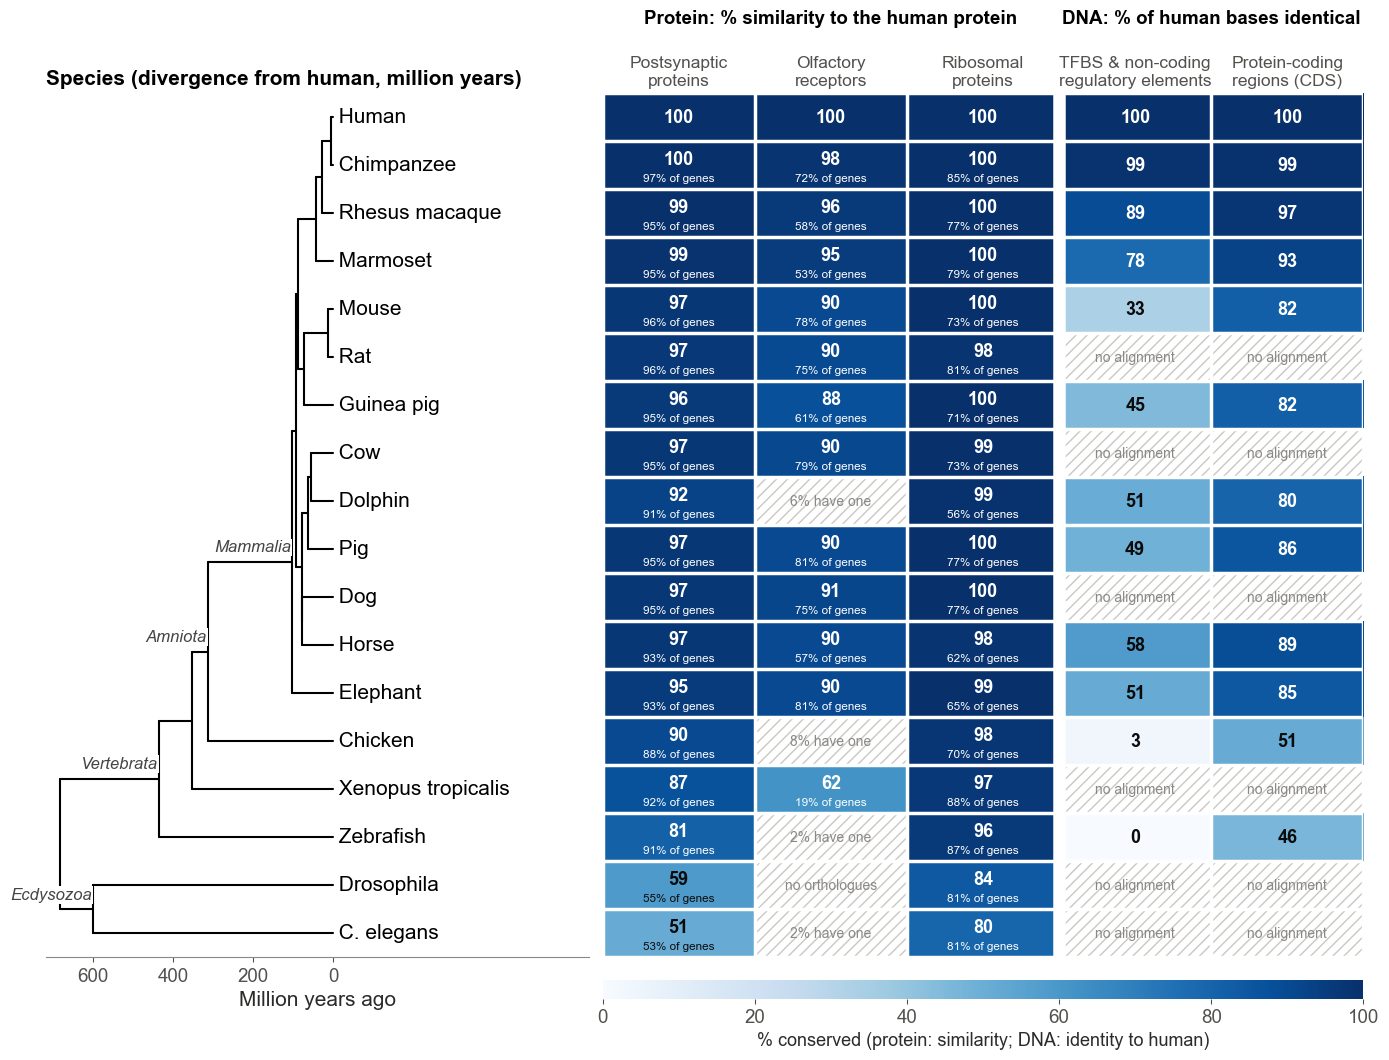

,Postsynaptic proteins,Olfactory receptors,Ribosomal proteins,TFBS & non-coding regulatory elements,Protein-coding regions (CDS)
Human,100 (100% of genes),100 (100% of genes),100 (100% of genes),100.0,100.0
Chimpanzee,100 (97% of genes),98 (72% of genes),100 (85% of genes),98.6,99.2
Rhesus macaque,99 (95% of genes),96 (58% of genes),100 (77% of genes),88.9,97.3
Marmoset,99 (95% of genes),95 (53% of genes),100 (79% of genes),77.6,92.5
Mouse,97 (96% of genes),90 (78% of genes),100 (73% of genes),33.1,81.7
Rat,97 (96% of genes),90 (75% of genes),98 (81% of genes),NaN,NaN
Guinea pig,96 (95% of genes),88 (61% of genes),100 (71% of genes),44.7,82.0
Cow,97 (95% of genes),90 (79% of genes),99 (73% of genes),NaN,NaN
Dolphin,92 (91% of genes),81 (6% of genes),99 (56% of genes),50.7,79.7
Pig,97 (95% of genes),90 (81% of genes),100 (77% of genes),48.8,85.5


In [3]:
# species tree + heatmap: how much of the human sequence each species keeps, for five kinds of sequence
# protein: % similarity (identical or similar residues); DNA: % identical bases
import importlib, re
import species_tree, evolution_conservation as ec
for m_ in (species_tree, ec):
    importlib.reload(m_)
from species_tree import build_tree, draw_species_tree, label_nodes

CACHE = os.path.join(POSTER, "conservation_cache")              # Ensembl answers, fetched once (fetch_conservation_v2.py)
mane = pd.read_csv(os.path.join(FIGURES, "..", "mane_transcripts.csv"))
mane = mane[mane.MANE_status == "MANE Select"]                    # one transcript per protein-coding gene
ensg = dict(zip(mane.symbol, mane.Ensembl_Gene))
GENE_SETS = {                                                     # column -> human genes (Ensembl IDs, MANE)
    "Postsynaptic\nproteins": [ensg[g] for g in psd_seq_df.gene if g in ensg],
    "Olfactory\nreceptors": [ensg[s] for s in mane.symbol if re.fullmatch(r"OR\d+[A-Z]+\d+[A-Z]?", str(s))],
    "Ribosomal\nproteins": [ensg[s] for s in mane.symbol if re.fullmatch(r"RP[LS]\d+[AXYL]?\d*|RPLP[0-2]|RPSA", str(s))],
}
REGION_SETS = {                                                   # column -> 80 human regions
    "TFBS & non-coding\nregulatory elements": lambda: ec.sample_regions("regulatory", 80, os.path.join(CACHE, "regulatory_regions.json")),
    "Protein-coding\nregions (CDS)": lambda: ec.sample_cds(mane.Ensembl_nuc.tolist(), 80, os.path.join(CACHE, "cds_regions.json")),
}

# protein columns: median % similarity among genes with an orthologue, and the share of genes that have one
identity, coverage = {}, {}
for col, genes in GENE_SETS.items():
    per_gene = ec.protein_similarity(genes, os.path.join(CACHE, "similarity"))  # 0 = no orthologue in that species
    identity[col] = ec.summarise(per_gene.where(per_gene > 0).median().to_frame().T)
    coverage[col] = ec.summarise(((per_gene > 0).mean() * 100).to_frame().T)
    print(f"{col.replace(chr(10), ' '):38s} {len(per_gene):5d} human genes")
# DNA columns: % of human bases identical in the species' pairwise genome alignment (NaN = no alignment)
aligned_species = ec.species_with_alignment()
for col, sample in REGION_SETS.items():
    regions = sample()
    identity[col] = ec.summarise(ec.dna_identity(regions, os.path.join(CACHE, "dna"), aligned_species))
    print(f"{col.replace(chr(10), ' '):38s} {len(regions):5d} human regions")

tree = build_tree(keep={"Human", *ec.SPECIES})                   # octopus and crow have no Ensembl data
tree.ladderize(reverse=True)                                      # human at the top
tips = [t.name for t in tree.get_terminals()]
table = pd.DataFrame(identity).reindex(tips)
table.loc["Human"] = 100.0                                        # the reference
cov = pd.DataFrame(coverage).reindex(tips); cov.loc["Human"] = 100.0
n, m = table.shape
n_protein = len(GENE_SETS)

fig = plt.figure(figsize=(17, 0.52 * n + 2.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1.75], height_ratios=[n, 0.4], wspace=0.02, hspace=0.05)
ax_tree, ax_hm, ax_cb = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])   # tree and heatmap share one row height
draw_species_tree(tree, ax=ax_tree, title="")
label_nodes(tree, ax_tree, names=["Mammalia", "Amniota", "Vertebrata", "Ecdysozoa"], fontsize=12)
ax_tree.set_xlim(ax_tree.get_xlim()[0], ax_tree.get_xlim()[1] * 1.55)          # room for the species names
ax_tree.set_title("Species (divergence from human, million years)", fontsize=15)
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("white")
shown = table.copy()
for col in GENE_SETS:
    shown.loc[cov[col] < 10, col] = np.nan                                     # too few orthologues: hatched, not coloured
im = ax_hm.imshow(shown.to_numpy(float), cmap=cmap, vmin=0, vmax=100, aspect="auto", extent=(-0.5, m - 0.5, n + 0.5, 0.5))
for i, sp in enumerate(tips, start=1):
    for j, col in enumerate(table.columns):
        val = table.loc[sp, col]
        cv = cov.loc[sp, col] if j < n_protein else np.nan
        if j < n_protein and cv < 10:                                         # (almost) no orthologues
            ax_hm.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", ec="#c9c8c3", lw=0))
            ax_hm.text(j, i, "no orthologues" if cv == 0 else f"{cv:.0f}% have one", ha="center", va="center", fontsize=10, color=MUTED)
        elif np.isnan(val):                                                    # no genome alignment to human
            ax_hm.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", ec="#c9c8c3", lw=0))
            ax_hm.text(j, i, "no alignment", ha="center", va="center", fontsize=10, color=MUTED)
        else:
            ink = "white" if val > 60 else INK
            if j < n_protein and sp != "Human":
                ax_hm.text(j, i - 0.12, f"{val:.0f}", ha="center", va="center", fontsize=13, color=ink, weight="bold")
                ax_hm.text(j, i + 0.27, f"{cv:.0f}% of genes", ha="center", va="center", fontsize=8.5, color=ink)
            else:
                ax_hm.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=13, color=ink, weight="bold")
ax_hm.set_xticks(np.arange(-0.5, m, 1), minor=True); ax_hm.set_yticks(np.arange(0.5, n + 1, 1), minor=True)
ax_hm.grid(which="minor", color="white", lw=2.5); ax_hm.tick_params(which="both", length=0)
ax_hm.axvline(n_protein - 0.5, color="white", lw=9)                          # gap between protein and DNA columns
ax_hm.set_xticks(range(m), table.columns, fontsize=12.5); ax_hm.xaxis.tick_top()
ax_hm.set_yticks([]); ax_hm.set_ylim(n + 0.5, 0.5); ax_tree.set_ylim(n + 0.5, 0.5)
for s_ in ax_hm.spines.values():
    s_.set_visible(False)
ax_hm.text((n_protein - 1) / 2, -0.95, "Protein: % similarity to the human protein", ha="center", fontsize=13.5, weight="bold")
ax_hm.text(n_protein + (m - n_protein - 1) / 2, -0.95, "DNA: % of human bases identical", ha="center", fontsize=13.5, weight="bold")
cb = fig.colorbar(im, cax=ax_cb, orientation="horizontal")
cb.set_label("% conserved (protein: similarity; DNA: identity to human)", fontsize=13); cb.outline.set_visible(False)
save(fig, "I0_conservation_phylogeny")
summary_tbl = table.round(1).astype(object)
for col in GENE_SETS:
    summary_tbl[col] = [f"{v:.0f} ({c:.0f}% of genes)" if np.isfinite(v) else f"– ({c:.0f}% of genes)" for v, c in zip(table[col], cov[col])]
summary_tbl.rename(columns=lambda c: c.replace(chr(10), " "))

## 4. Introduction: ESM-1v separates healthy-population from pathogenic variants
`I1_esm_by_variant_group.svg`

**Data.** These are the held-out variants of notebook 05 §6g: 10% of all variants, drawn at random within each gene and database *before* any score was built. They were used to judge scores, never to make them.
- A variant found in both databases is grouped by its ClinVar classification; most ClinVar-benign variants are also in gnomAD.
- "gnomAD" means present in gnomAD (allele count ≥ 2) and not in ClinVar.

**Score.** ESM-1v's LLR of the substitution, log P(new amino acid) − log P(original), computed once in 05 §4. Negative means evolution finds the change unexpected; the more negative, the more damaging it looks.

**How to read it.** Each box spans the middle half of a group, the black line is the median, the diamond the mean, and whiskers reach 1.5× the box height. The cell prints the means and three AUROCs:
- **gnomAD vs pathogenic:** can the score tell them apart?
- **gnomAD vs VUS:** do VUS look different from healthy-population variants?
- **VUS vs pathogenic.**

**What it shows.** ESM-1v separates gnomAD from pathogenic variants (AUROC 0.80), but scores VUS almost exactly like gnomAD variants (AUROC 0.48). Evolution alone has little to say about most VUS.

**Caption (copy-ready).** *ESM-1v LLR of held-out missense variants. Pathogenic variants score far lower than gnomAD variants (means −10.5 vs −5.8; AUROC 0.80), but VUS are indistinguishable from gnomAD variants (AUROC 0.48).*

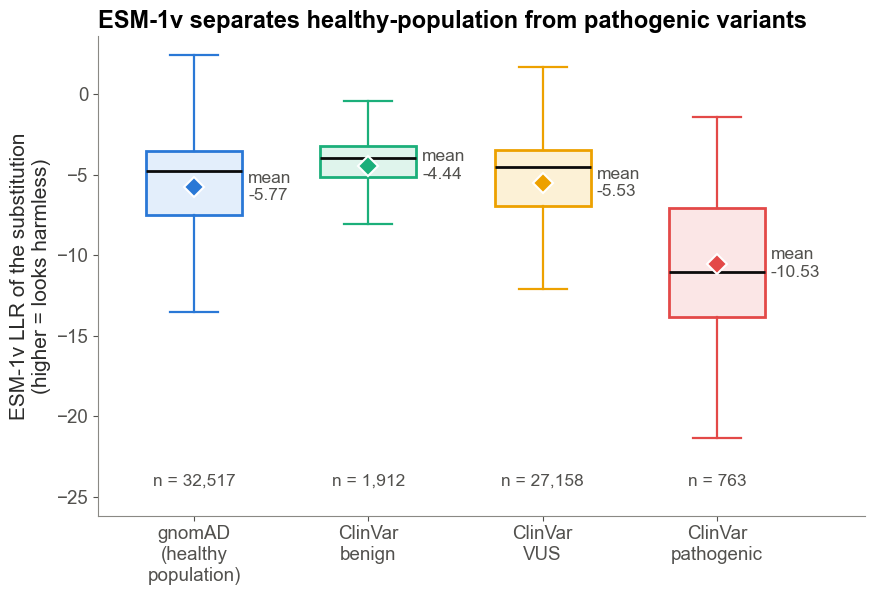

mean                         {'gnomAD only': -5.774, 'ClinVar benign': -4.438, 'ClinVar vus': -5.53, 'ClinVar pathogenic': -10.527}
n                            {'gnomAD only': 32517, 'ClinVar benign': 1912, 'ClinVar vus': 27158, 'ClinVar pathogenic': 763}
AUROC gnomAD vs pathogenic   0.8
AUROC gnomAD vs VUS          0.475
AUROC VUS vs pathogenic      0.813


In [4]:
# held-out variants, one row each; grouped by source and ClinVar classification (as in 05 §6g)
v = val_scored.sort_values("database").drop_duplicates("id").copy()   # 'ClinVar' sorts first: both-database variants keep their label
v["group"] = np.where(v.database == "GnomAD", "gnomAD only", "ClinVar " + v.clinsig_group.astype(str))
GROUPS = [("gnomAD only", "gnomAD\n(healthy\npopulation)", BLUE), ("ClinVar benign", "ClinVar\nbenign", AQUA),
          ("ClinVar vus", "ClinVar\nVUS", YELLOW), ("ClinVar pathogenic", "ClinVar\npathogenic", RED)]
group_stats = {}


def by_group(col, ylabel, title, name):
    '''Box plot of one score across the four variant groups, with means, counts and three AUROCs.'''
    fig, ax = plt.subplots(figsize=(9, 6.2))
    data = [v.loc[v.group == g, col].dropna() for g, _, _ in GROUPS]
    bp = ax.boxplot(data, showfliers=False, widths=0.55, patch_artist=True, medianprops=dict(color=INK, lw=2))
    for patch, (_, _, c) in zip(bp["boxes"], GROUPS):
        patch.set(facecolor=TINT[c], edgecolor=c, lw=2)
    for el in ["whiskers", "caps"]:
        for k, line in enumerate(bp[el]):
            line.set(color=GROUPS[k // 2][2], lw=1.6)
    lo_, hi_ = ax.get_ylim()
    for k, (d, (g, _, c)) in enumerate(zip(data, GROUPS), 1):
        ax.plot(k, d.mean(), "D", color=c, ms=10, mec="white", mew=1.5, zorder=4)
        ax.text(k + 0.31, d.mean(), f"mean\n{d.mean():+.2f}", va="center", fontsize=12.5, color=INK2)
        ax.text(k, lo_ - (hi_ - lo_) * 0.04, f"n = {len(d):,}", ha="center", va="top", fontsize=12.5, color=INK2)
    ax.set_ylim(lo_ - (hi_ - lo_) * 0.14, hi_)
    ax.set_xticks(range(1, len(GROUPS) + 1), [lab_ for _, lab_, _ in GROUPS])
    ax.set_xlim(0.45, len(GROUPS) + 0.85)
    ax.set_ylabel(ylabel); ax.set_title(title)
    gn, vus, path = data[0], data[2], data[3]
    auc = lambda a, b: roc_auc_score(np.r_[np.ones(len(a)), np.zeros(len(b))], np.r_[a, b])   # a should score higher
    stats = {"mean": {g: round(float(d.mean()), 3) for (g, _, _), d in zip(GROUPS, data)},
             "n": {g: int(len(d)) for (g, _, _), d in zip(GROUPS, data)},
             "AUROC gnomAD vs pathogenic": round(auc(gn, path), 3), "AUROC gnomAD vs VUS": round(auc(gn, vus), 3),
             "AUROC VUS vs pathogenic": round(auc(vus, path), 3)}
    group_stats[col] = stats
    fig.tight_layout(); save(fig, name)
    for k_, val in stats.items():
        print(f"{k_:28s} {val}")


by_group("esm_llr", "ESM-1v LLR of the substitution\n(higher = looks harmless)",
         "ESM-1v separates healthy-population from pathogenic variants", "I1_esm_by_variant_group")

## 5. Methods 1a: how the tolerance score is built (diagram)
`M0_tolerance_diagram.svg`

**What it shows.** A simulated 180-residue protein: two structured domains with an unstructured (disordered) stretch between them, shaded yellow.
- The variants are made up.
- Everything computed from them uses the real recipe: `convolve_v4` with the same settings as notebook 05 (`tolerance.V4_PARAMS`). So the shapes are what the method actually produces.

**How to read it, from the bar outwards**
- **The bar** holds three heatmaps aligned residue by residue:
  - **top lane:** ClinVar density (white → red);
  - **middle lane:** tolerance = gnomAD − ClinVar (blue = tolerated, red = intolerant);
  - **bottom lane:** gnomAD density (white → blue).
- **Lollipops:** ClinVar variants above the bar, gnomAD variants below it.
  - Stem height shows how drastic the substitution is, on a 0–1 scale (all heads are the same size).
  - The scale is BLOSUM62 dissimilarity where the variant's residue is structured, and Grantham distance / 215 where it is disordered.
- **Rolling windows** (black bell curves): the density at a residue is the weighted average of the lollipops under a binomial window centred on that residue.
  - The window is wide where the residue is structured (w = 31; it reaches 63 residues).
  - It is narrow where the residue is disordered (w = 5; 11 residues).
  - Each density is then scaled 0–1 within the protein.
- **Density curves:** the window has slid from residue 1 to where it is drawn. The curve it has traced so far has a translucent fill: ClinVar above, gnomAD below (pointing down). The dashed line links each window to the value it produces.
- **What to notice:**
  - In the disordered stretch, the gnomAD curve follows individual variants: narrow window, sharp peaks. In the structured domains it is smooth.
  - Where ClinVar variants cluster in the second domain, the ClinVar density is high and the tolerance lane turns red.

**A detail worth knowing.** A binomial window puts most of its weight near its centre:
- w = 31: about 97% of the weight lies within ±8 residues;
- w = 5: about 98% lies within ±3.

So "±31 residues" is the window's reach, not its effective width.

**Caption (copy-ready).** *How the tolerance score is built (schematic, simulated protein). ClinVar (above) and gnomAD (below) missense variants are weighted by substitution severity (lollipop height: BLOSUM62 in structured, Grantham in unstructured regions). They are averaged with a binomial rolling window, wide in structured regions (w = 31) and narrow in unstructured regions (w = 5). The two densities are scaled 0–1 and subtracted: tolerance = gnomAD − ClinVar (middle lane; blue = tolerated, red = intolerant).*

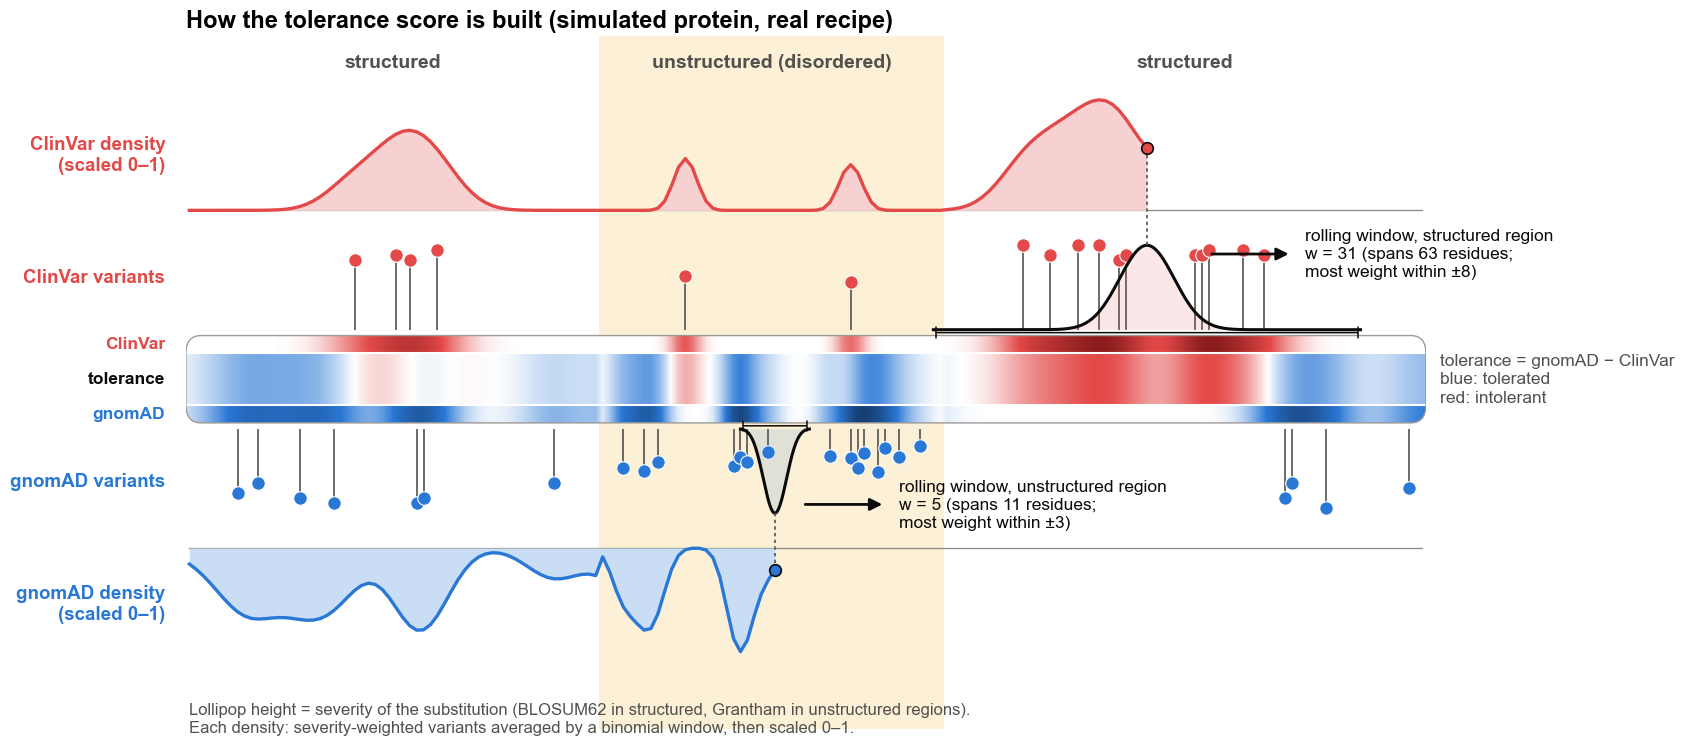

In [5]:
# Schematic: how the tolerance score is built, on a SIMULATED 180-residue protein.
# The variants are made up; everything computed from them uses the real recipe (convolve_v4 with
# tolerance.V4_PARAMS): severity weights, binomial windows, max per residue, min-max scaling, subtraction.
from matplotlib.colors import LinearSegmentedColormap
from scipy.interpolate import make_interp_spline
from convolve import convolve_v4, substitution_weight
from tolerance import V4_PARAMS, normalize



def draw_tolerance_diagram(seed=3):
    '''Draw the schematic; every name stays inside this function (nothing in the notebook is overwritten).'''
    rng = np.random.default_rng(seed)
    L, DIS = 180, (61, 110)                                   # protein length; the unstructured (disordered) stretch
    x = np.arange(1, L + 1)
    is_dis = (x >= DIS[0]) & (x <= DIS[1])
    disorder = np.where(is_dis, 0.8, 0.15)                     # AIUPred-like score: >= 0.5 counts as disordered
    seq = "".join(rng.choice(list("PSGEKQADNRT" if d else "ACDEFGHIKLMNPQRSTVWY")) for d in is_dis)


    def make_variants(positions, severe):
        '''One substitution per position; severe=True keeps the most radical of 3 random swaps, else the mildest.'''
        out = []
        for p in sorted(positions):
            ref = seq[p - 1]
            alts = rng.choice([a for a in "ACDEFGHIKLMNPQRSTVWY" if a != ref], 3, replace=False)
            matrix = "grantham" if is_dis[p - 1] else "blosum62"    # the variant's OWN residue picks the matrix
            sev = {a: substitution_weight(ref, a, matrix) for a in alts}
            alt = (max if severe else min)(sev, key=sev.get)
            out.append((p, f"{ref}{p}{alt}", sev[alt]))
        return out


    pick = lambda lo, hi, k: rng.choice(np.arange(lo, hi + 1), k, replace=False).tolist()
    gnomad = make_variants(pick(4, 55, 7) + pick(63, 108, 15) + pick(160, 178, 4), severe=False)
    clinvar = make_variants(pick(18, 45, 4) + pick(70, 100, 2) + pick(122, 158, 11), severe=True)
    g = normalize(convolve_v4([v for _, v, _ in gnomad], L, adjustment_list=list(disorder), **V4_PARAMS))
    c = normalize(convolve_v4([v for _, v, _ in clinvar], L, adjustment_list=list(disorder), **V4_PARAMS))
    tol_sim = g - c

    XC, WC = 140, 31                                           # ClinVar window: structured region, w = 31
    XG, WG = 86, 5                                             # gnomAD window: unstructured region, w = 5
    BAR, LANE = 0.75, 0.3                                      # bar half-height; ClinVar / gnomAD lane height
    STEM0, STEM = 0.85, 1.3                                    # lollipops start just off the bar; height ~ severity
    CB, CA = 2.9, 1.9                                          # density curves: baseline distance and amplitude

    fig, ax = plt.subplots(figsize=(16, 9))
    ax.axvspan(DIS[0] - 0.5, DIS[1] + 0.5, color=TINT[YELLOW], lw=0, zorder=0)

    # ---- the protein: three aligned heatmaps in one bar (ClinVar density / tolerance / gnomAD density)
    bar = FancyBboxPatch((0.5, -BAR), L, 2 * BAR, boxstyle="round,pad=0,rounding_size=2.2", mutation_aspect=0.14,
                         fc="none", ec="#9b9a96", lw=1, zorder=4)
    ax.add_patch(bar)
    tol_cmap = LinearSegmentedColormap.from_list("tol", [RED, "#ffffff", BLUE])
    lanes = [(c, BAR - LANE, BAR, LinearSegmentedColormap.from_list("cv", ["#ffffff", RED, "#8c1d1d"]), 0, 1),
             (tol_sim, -BAR + LANE, BAR - LANE, tol_cmap, -1, 1),
             (g, -BAR, -BAR + LANE, LinearSegmentedColormap.from_list("gn", ["#ffffff", BLUE, "#163f73"]), 0, 1)]
    for vals, y0, y1, cmap, lo, hi in lanes:
        im = ax.imshow(np.asarray(vals)[None, :], extent=(0.5, L + 0.5, y0, y1), cmap=cmap, vmin=lo, vmax=hi,
                       aspect="auto", interpolation="bilinear", zorder=2)
        im.set_clip_path(bar)
    ax.hlines([BAR - LANE, -BAR + LANE], 0.5, L + 0.5, color="white", lw=1.5, zorder=3)

    # ---- lollipops: ClinVar above, gnomAD below; stem height = substitution severity (0-1)
    for variants, sign, colour in [(clinvar, 1, RED), (gnomad, -1, BLUE)]:
        p = np.array([v[0] for v in variants]); sev = np.array([v[2] for v in variants])
        tip = sign * (STEM0 + 0.15 + sev * STEM)
        ax.vlines(p, sign * STEM0, tip, color=INK2, lw=1.2, zorder=5)
        ax.scatter(p, tip, s=95, color=colour, ec="white", lw=0.8, zorder=6)   # same head size for all: only the stem shows severity


    def window(center, w, sign, colour):
        '''Draw the binomial kernel (2w+1 residues, weights sum to 1) over the lollipops it averages.'''
        off = np.arange(-w, w + 1)
        k = binom.pmf(off + w, 2 * w, 0.5)
        fine = np.linspace(-w, w, 400)
        kf = np.clip(make_interp_spline(off, k / k.max(), k=3)(fine), 0, None)
        base, top = sign * STEM0, sign * (STEM0 + 0.15 + STEM)
        ax.fill_between(center + fine, base, base + (top - base) * kf, color=colour, alpha=0.13, lw=0, zorder=6)
        ax.plot(center + fine, base + (top - base) * kf, color=INK, lw=2.2, zorder=7)
        ax.annotate("", (center - w, base - sign * 0.05), (center + w, base - sign * 0.05), zorder=7,
                    arrowprops=dict(arrowstyle="|-|,widthA=0.25,widthB=0.25", color=INK, lw=1.1))
        return top


    def density(vals, upto, sign, colour, center_top):
        '''The smoothed density traced so far: residues 1 .. upto, with a translucent fill.'''
        base = sign * CB
        xs = x[:upto]; ys = base + sign * CA * np.asarray(vals)[:upto]
        ax.fill_between(xs, base, ys, color="white", lw=0, zorder=2)            # keeps the tint the same over both regions
        ax.fill_between(xs, base, ys, color=colour, alpha=0.25, lw=0, zorder=2.1)
        ax.plot(xs, ys, color=colour, lw=2.4, zorder=3)
        ax.plot([1, L], [base, base], color=MUTED, lw=0.9, zorder=1)
        ax.scatter([upto], [ys[-1]], s=70, color=colour, ec=INK, lw=1.2, zorder=8)
        ax.plot([upto, upto], [center_top, ys[-1]], ls=(0, (2, 2)), color=INK2, lw=1.2, zorder=7)


    apex_c = window(XC, WC, 1, RED)
    apex_g = window(XG, WG, -1, BLUE)
    density(c, XC, 1, RED, apex_c)
    density(g, XG, -1, BLUE, apex_g)
    for xc, w, sign, apex in [(XC, WC, 1, apex_c), (XG, WG, -1, apex_g)]:              # "the window slides" arrows
        a0 = xc + (9 if w > 10 else 4)
        ax.annotate("", (a0 + 12, apex - sign * 0.15), (a0, apex - sign * 0.15),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=2, mutation_scale=18), zorder=8)
    ax.text(XC + 23, apex_c - 0.15, "rolling window, structured region\nw = 31 (spans 63 residues;\nmost weight within ±8)",
            fontsize=12.5, va="center", color=INK, linespacing=1.25)
    ax.text(XG + 18, apex_g + 0.15, "rolling window, unstructured region\nw = 5 (spans 11 residues;\nmost weight within ±3)",
            fontsize=12.5, va="center", color=INK, linespacing=1.25)

    # ---- labels
    for (a, b), name in [((1, DIS[0] - 1), "structured"), (DIS, "unstructured (disordered)"), ((DIS[1] + 1, L), "structured")]:
        ax.text((a + b) / 2, CB + CA + 0.55, name, ha="center", fontsize=14, weight="bold", color=INK2)
    LX = -2.5
    for y, txt, col in [(CB + CA / 2, "ClinVar density\n(scaled 0–1)", RED), (STEM0 + 0.9, "ClinVar variants", RED),
                        (BAR - LANE / 2, "ClinVar", RED), (0, "tolerance", INK), (-BAR + LANE / 2, "gnomAD", BLUE),
                        (-STEM0 - 0.9, "gnomAD variants", BLUE), (-CB - CA / 2, "gnomAD density\n(scaled 0–1)", BLUE)]:
        ax.text(LX, y, txt, ha="right", va="center", fontsize=13.5 if "\n" in txt or "variants" in txt else 12.5,
                color=col, weight="bold" if col != INK else "bold", linespacing=1.2)
    ax.text(L + 2.5, 0, "tolerance = gnomAD − ClinVar\nblue: tolerated\nred: intolerant", ha="left", va="center",
            fontsize=12.5, color=INK2, linespacing=1.3)
    ax.text(1, -CB - CA - 0.75, "Lollipop height = severity of the substitution (BLOSUM62 in structured, Grantham in unstructured "
            "regions).\nEach density: severity-weighted variants averaged by a binomial window, then scaled 0–1.",
            fontsize=12, color=INK2, va="top")
    ax.set_xlim(0.5, L + 0.5); ax.set_ylim(-CB - CA - 1.2, CB + CA + 1.1)
    ax.axis("off")
    ax.set_title("How the tolerance score is built (simulated protein, real recipe)", loc="left", pad=6)
    return fig


save(draw_tolerance_diagram(), "M0_tolerance_diagram")

## 6. Methods 1b: the tolerance score on a real gene (GLRA1)
`M1_tolerance_score_build.svg`

The same three steps run for every gene; GLRA1 (glycine receptor α1, 449 residues) is shown.
1. **Which variants count.**
   - gnomAD variants seen at least twice (allele count ≥ 2). On chrX/Y, only those carried by a male or a homozygous female, because a variant seen only in heterozygous women may be a masked recessive allele.
   - Every ClinVar missense variant, whatever its classification.
2. **Weight and smooth.**
   - **Weight:** each variant counts by how drastic its substitution is: BLOSUM62 in ordered regions, Grantham distance in disordered regions (AIUPred disorder ≥ 0.5). Where several variants share a residue, the most drastic counts.
   - **Smooth:** the weight is spread over the neighbours with a bell-shaped (binomial) kernel: ±31 residues in ordered regions, ±5 in disordered ones.
3. **Subtract.** Each density is scaled 0–1 within the gene, and tolerance = gnomAD − ClinVar. Above 0: more healthy variation than disease reports (tolerated). Below 0: intolerant.

**Caption (copy-ready).** *Tolerance score construction for GLRA1. (1) gnomAD (up) and ClinVar (down) missense variants. (2) Each variant is weighted by substitution severity and smoothed along the protein. (3) Tolerance = scaled gnomAD density − scaled ClinVar density. The pathogenic variant p.A300P lies in an intolerant region.*

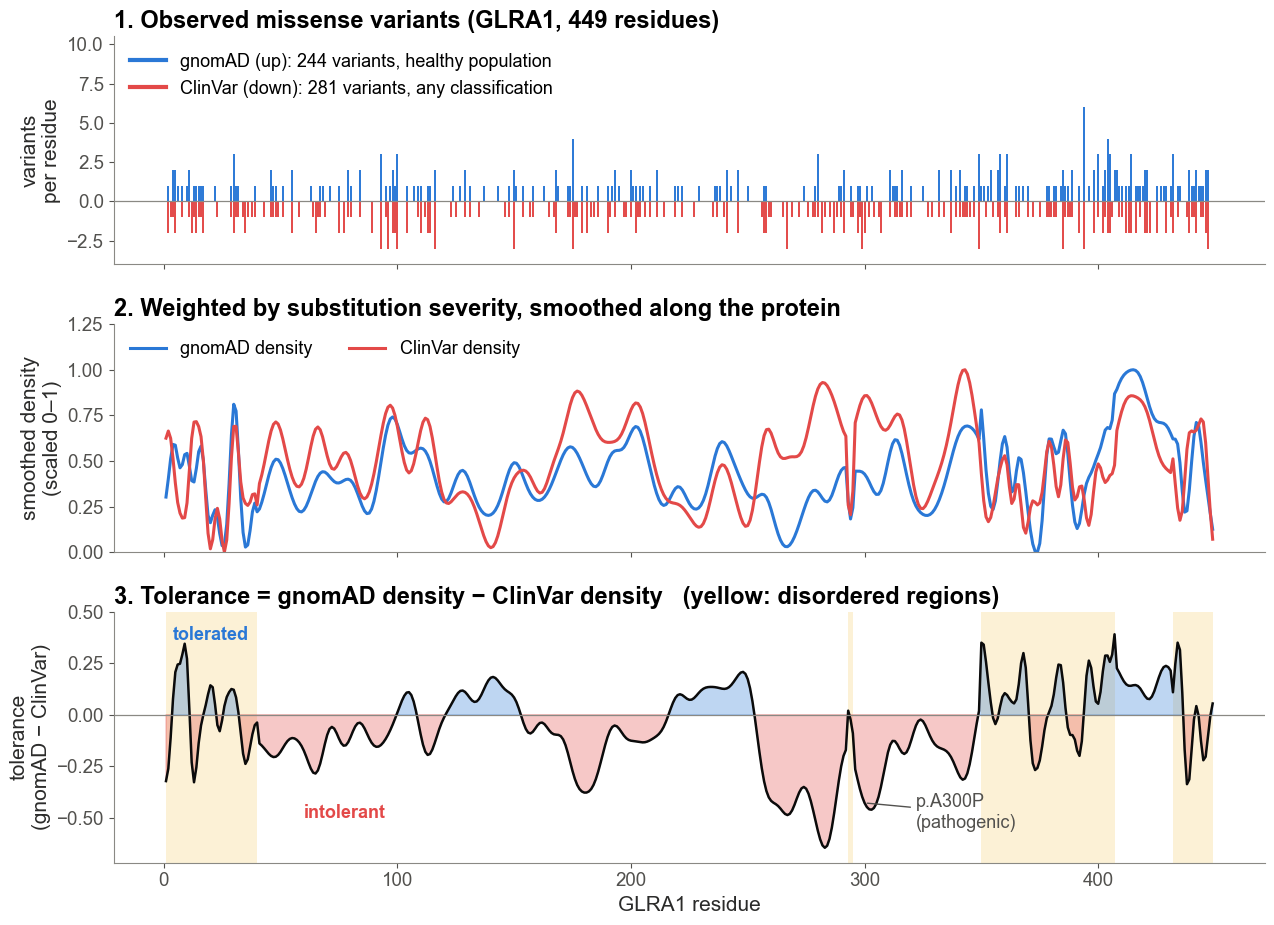

GLRA1: tolerance at residue 300 = -0.43; gene median -0.08


In [6]:
tol = pd.read_parquet(os.path.join(OUT, "tolerance_v4.parquet")).set_index("gene").loc[GENE]
L = len(tol.sequence); x = np.arange(1, L + 1)
gv = tolerance_variants[tolerance_variants.gene == GENE]            # the variants that feed the score (05 §3)
gn_cnt = np.bincount(gv.position[gv.database == "GnomAD"] - 1, minlength=L)
cv_cnt = np.bincount(gv.position[gv.database == "ClinVar"] - 1, minlength=L)
norm = lambda a: (np.asarray(a) - np.min(a)) / (np.ptp(a) or 1)
dis = np.asarray(tol.disorder_scores); t = np.asarray(tol.tolerance_v4)

fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True, gridspec_kw={"height_ratios": [1, 1, 1.1]})
ax = axes[0]
ax.vlines(x[gn_cnt > 0], 0, gn_cnt[gn_cnt > 0], color=BLUE, lw=1.4)
ax.vlines(x[cv_cnt > 0], 0, -cv_cnt[cv_cnt > 0], color=RED, lw=1.4)
ax.axhline(0, color=MUTED, lw=0.9); ax.set_ylim(-cv_cnt.max() - 1, gn_cnt.max() + 4.5)
ax.set_ylabel("variants\nper residue")
ax.legend(handles=[Line2D([], [], color=BLUE, lw=3, label=f"gnomAD (up): {int((gv.database == 'GnomAD').sum())} variants, healthy population"),
                   Line2D([], [], color=RED, lw=3, label=f"ClinVar (down): {int((gv.database == 'ClinVar').sum())} variants, any classification")],
          frameon=False, loc="upper left", fontsize=13)
ax.set_title(f"1. Observed missense variants ({GENE}, {L} residues)")
ax = axes[1]
ax.plot(x, norm(tol.gnomad_y_v4), color=BLUE, lw=2.2, label="gnomAD density")
ax.plot(x, norm(tol.clinvar_y_v4), color=RED, lw=2.2, label="ClinVar density")
ax.set_ylabel("smoothed density\n(scaled 0–1)"); ax.legend(frameon=False, ncol=2, loc="upper left", fontsize=13)
ax.set_ylim(0, 1.25)
ax.set_title("2. Weighted by substitution severity, smoothed along the protein")
ax = axes[2]
ax.fill_between(x, 0, 1, where=dis >= 0.5, transform=ax.get_xaxis_transform(), color=TINT[YELLOW], lw=0, step="mid")
ax.plot(x, t, color=INK, lw=1.8)
ax.fill_between(x, t, 0, where=t > 0, color=BLUE, alpha=0.3, interpolate=True)
ax.fill_between(x, t, 0, where=t < 0, color=RED, alpha=0.3, interpolate=True)
ax.axhline(0, color=MUTED, lw=0.9)
ax.annotate(f"p.A{VAR_POS}P\n(pathogenic)", (VAR_POS, t[VAR_POS - 1]), (VAR_POS + 22, -0.55), fontsize=13,
            arrowprops=dict(arrowstyle="-", color=INK2, lw=1), color=INK2)
ax.text(4, 0.43, "tolerated", color=BLUE, fontsize=13, weight="bold", va="top")
ax.text(60, -0.5, "intolerant", color=RED, fontsize=13, weight="bold")
ax.set_ylim(-0.72, 0.5); ax.set_ylabel("tolerance\n(gnomAD − ClinVar)"); ax.set_xlabel(f"{GENE} residue")
ax.set_title("3. Tolerance = gnomAD density − ClinVar density   (yellow: disordered regions)")
fig.tight_layout(); save(fig, "M1_tolerance_score_build")
print(f"{GENE}: tolerance at residue {VAR_POS} = {t[VAR_POS - 1]:+.2f}; gene median {np.median(t):+.2f}")

## 7. Methods 1c: tolerance by variant group
`M2_tolerance_by_variant_group.svg`

**Data.** The same held-out variants as the introduction figure. Each one is scored on a tolerance track rebuilt from the *other* 90% of variants (`tolerance_v4_train`), so no variant contributes to its own score.

**What it shows.**
- **Order:** mean tolerance falls from gnomAD (+0.20) through ClinVar-benign (+0.06) and VUS (+0.04) to pathogenic (−0.34).
- **gnomAD vs pathogenic:** tolerance separates them better than ESM-1v does (AUROC 0.90 vs 0.80).
- **VUS:** unlike ESM-1v, tolerance places VUS below gnomAD variants (AUROC 0.67).

**Read the VUS result carefully.** The VUS mean is almost the same as ClinVar-benign and far from pathogenic. The ClinVar side of the score counts every ClinVar submission, VUS included, so a held-out VUS tends to sit near other ClinVar entries. Part of its lower tolerance comes from that clustering of submissions, not from pathogenicity. A fair statement: *VUS fall between gnomAD and pathogenic variants, close to ClinVar-benign variants.*

**Caption (copy-ready).** *Tolerance of held-out variants, scored on tracks rebuilt without them. Mean tolerance: gnomAD +0.20, ClinVar benign +0.06, VUS +0.04, pathogenic −0.34. Tolerance separates gnomAD from pathogenic variants (AUROC 0.90; ESM-1v 0.80) and, unlike ESM-1v, places VUS between the two.*

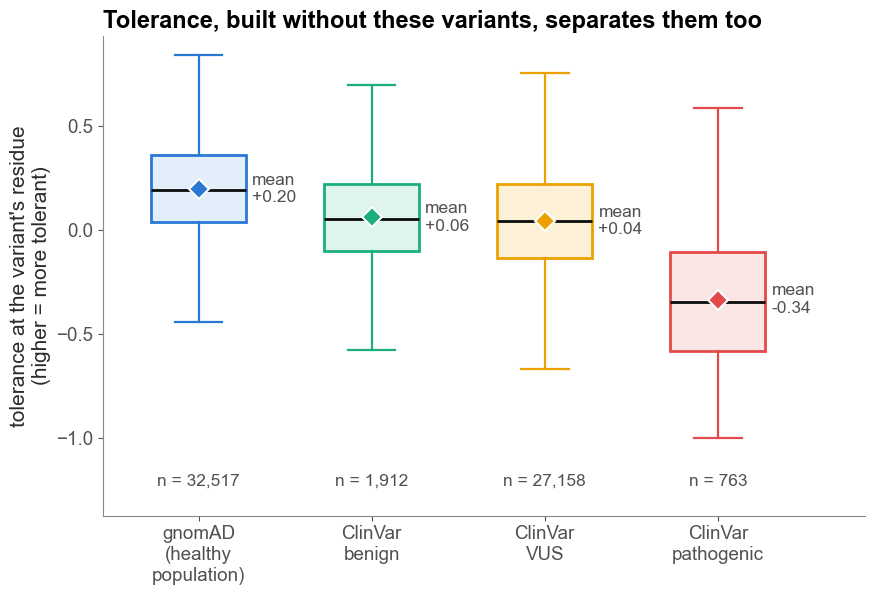

mean                         {'gnomAD only': 0.196, 'ClinVar benign': 0.059, 'ClinVar vus': 0.041, 'ClinVar pathogenic': -0.336}
n                            {'gnomAD only': 32517, 'ClinVar benign': 1912, 'ClinVar vus': 27158, 'ClinVar pathogenic': 763}
AUROC gnomAD vs pathogenic   0.896
AUROC gnomAD vs VUS          0.665
AUROC VUS vs pathogenic      0.805


In [7]:
by_group("tolerance_v4_train", "tolerance at the variant's residue\n(higher = more tolerant)",
         "Tolerance, built without these variants, separates them too", "M2_tolerance_by_variant_group")

## 8. Methods 2: protein structure, dissecting GLRA1
Before any model sees a variant, every residue is described by its structural context:
- Is it in a structured region?
- Is it buried or exposed?
- Does it touch another protein?
- Does it sit in a known domain, motif or binding site?

This section shows each step on the running example, **GLRA1** (glycine receptor α1), a chloride channel at inhibitory synapses. Five subunits form a ring around a central channel, and the neurotransmitter glycine binds between neighbouring subunits.

**Structures**
- **AlphaFold model of UniProt isoform 2 (P23415-2).** Its sequence is exactly the MANE sequence (449 residues), so its numbering matches every feature without any mapping.
- **PDB 8DN5:** a cryo-EM structure (3.63 Å) of the human α1β glycine receptor **with glycine bound** (open state; *Nature Communications*, 2023).
  - Chains A–D are α1 and chain E is β; one glycine sits at each of the five subunit interfaces.
  - 8DN5 numbers the mature protein (without the 28-residue signal peptide), so every chain is aligned to the MANE sequence. All 341 residues of chain A match.
- **The model's burial values (RSA) were computed on 8DN3,** the apo structure of the same receptor from the same study (chain A, 336 residues). The figures colour 8DN5's residues with those values.

**How the pictures are drawn.** The pictures are drawn from the atomic coordinates with matplotlib (`figures/struct_render.py`):
- **Ribbons** for helices and strands. Secondary structure comes from backbone hydrogen bonds (a simplified DSSP).
- **A thin tube** for loops.
- **One sphere per residue,** at its side-chain centre.

The molecule is embedded as a 300-dpi image inside each SVG. Every label, arrow, legend and number stays editable text.

The cell below does five things:
1. loads both structures;
2. maps them onto MANE positions;
3. finds which residues of subunit A touch another subunit;
4. finds which residues hold each glycine;
5. counts how often held-out ClinVar variants in each structural class are pathogenic (as in notebook 05 §7f).

In [8]:
# GLRA1 structures for Methods 2: the AlphaFold model (whole protein) and the human a1-beta receptor with glycine bound (PDB 8DN5)
import importlib, urllib.request, collections
import struct_render
importlib.reload(struct_render)
from struct_render import read_structure, chain_residues, secondary_structure, view_matrix, rotate_about, Scene
from Bio import Align
from Bio.PDB import NeighborSearch

STRUCT = os.path.join(OUT, "structure_cache")
AF_FILE = os.path.join(STRUCT, "af", "AF-P23415-2-F1.pdb")      # AlphaFold model of UniProt isoform 2 = the MANE sequence
CIF_FILE = os.path.join(STRUCT, "assembly", "8dn5.cif")         # cryo-EM, 3.63 A, glycine-bound (open): a1 x 4 (A-D) + beta (E)
if not os.path.exists(CIF_FILE):
    os.makedirs(os.path.dirname(CIF_FILE), exist_ok=True)
    urllib.request.urlretrieve("https://files.rcsb.org/download/8DN5.cif", CIF_FILE)

STRUCTURED, UNSTRUCTURED, GLYCINE_COLOUR = "#4f6d8f", YELLOW, ORANGE
CLASS_COLOUR = {"core": AQUA, "boundary": "#8fcfb6", "surface": "#cfe9de", "interface": VIOLET}   # as in the M3 tracks
CLASS_LABEL = {"core": "core (RSA < 0.2)", "boundary": "boundary (0.2–0.4)", "surface": "surface (RSA > 0.4)",
               "interface": "interface (exposed, touching\nanother subunit)"}

gr = residue_df[residue_df.gene == GENE].sort_values("pos").set_index("pos")    # the model's per-residue features
MANE_SEQ = "".join(gr.aa)


def runs(mask, start=1):
    '''[(first, last), ...] residue numbers of the True stretches of a boolean array.'''
    out, i, m = [], 0, np.asarray(mask, bool)
    while i < len(m):
        if m[i]:
            j = i
            while j < len(m) and m[j]:
                j += 1
            out.append((i + start, j - 1 + start)); i = j
        else:
            i += 1
    return out


TM = runs(gr.ann_transmembrane.fillna(False).to_numpy())        # M1-M4 (UniProt, in MANE numbering)
UNSTRUCT = gr.disorder.to_numpy() >= 0.5                          # the model's definition (AIUPred >= 0.5)

# ---- AlphaFold model: the whole protein, numbered exactly like the MANE sequence
af = chain_residues(AF_FILE, "A")
af_ss = secondary_structure(af)
assert af.aa == MANE_SEQ, "the AlphaFold model should match the MANE sequence"

# ---- 8DN5: map every a1 chain onto MANE positions by sequence alignment (its author numbering is the mature protein's)
glyr = read_structure(CIF_FILE)
CH = {c.id: chain_residues(glyr, c.id) for c in glyr[0]}
CH_SS = {k: secondary_structure(v) for k, v in CH.items()}


def mane_positions(r):
    al = Align.PairwiseAligner(); al.mode = "global"; al.open_gap_score = -10; al.extend_gap_score = -0.5
    a = al.align(r.aa, MANE_SEQ)[0]
    out = np.full(len(r), -1)
    for (s1, e1), (s2, e2) in zip(*a.aligned):
        out[s1:e1] = np.arange(s2, e2) + 1
    return out


POS = {k: mane_positions(CH[k]) for k in "ABCD"}
A, posA = CH["A"], POS["A"]
assert all(A.aa[i] == MANE_SEQ[p - 1] for i, p in enumerate(posA) if p > 0)

# ---- protein-protein contacts (heavy atoms within 4.5 A; sugars, lipids and glycine don't count)
protein_atoms = [a for a in glyr[0].get_atoms() if a.get_parent().id[0] == " " and a.element != "H"]
ns = NeighborSearch(protein_atoms)
touch = collections.defaultdict(set)                      # chain A residue -> chains it touches
touched = collections.defaultdict(set)                    # other chain -> its residues that touch chain A
for atom in glyr[0]["A"].get_atoms():
    if atom.get_parent().id[0] != " ":
        continue
    for other in ns.search(atom.coord, 4.5):
        ch = other.get_parent().get_parent().id
        if ch != "A":
            touch[atom.get_parent().id[1]].add(ch)
            touched[ch].add(other.get_parent().id[1])
contactA = np.array([bool(touch.get(int(n))) for n in A.num])
partnerA = np.array(["".join(sorted(touch.get(int(n), []))) for n in A.num])
rsa_classA = gr.rsa_class.reindex(posA).astype("object").to_numpy()
classA = np.where(contactA & np.isin(rsa_classA, ["surface", "boundary"]), "interface", rsa_classA)
kb_ifaceA = gr.iface_any.reindex(posA).fillna(False).to_numpy().astype(bool)
NEIGHBOURS = sorted({c for s in touch.values() for c in s})

# ---- the bound glycines: one per subunit interface; which residues of which chains hold each one
GLYCINES = []
for r in (r for c in glyr[0] for r in c if r.id[0].startswith("H_") and r.get_resname() == "GLY"):
    xyz = np.array([a.coord for a in r if a.element != "H"])
    site = collections.defaultdict(set)
    for a in r:
        for b in ns.search(a.coord, 4.0):
            site[b.get_parent().get_parent().id].add(b.get_parent().id[1])
    GLYCINES.append({"xyz": xyz, "site": dict(site)})
GLY_A = [g for g in GLYCINES if "A" in g["site"]]                # the two glycine sites subunit A takes part in

# ---- orientation: pore axis = normal of the plane through the five subunit centres; up = toward the ECD
cents = np.array([CH[k].ca.mean(0) for k in "ABCDE"])
UP = np.linalg.svd(cents - cents.mean(0))[2][2]
tm_maskA = np.zeros(len(A), bool)
for s0, e0 in TM:
    tm_maskA |= (posA >= s0) & (posA <= e0)
TMD_CENTRE = A.ca[tm_maskA].mean(0)                                        # the membrane's middle, in subunit A
if (A.ca[(posA > 28) & (posA < 246)].mean(0) - TMD_CENTRE) @ UP < 0:
    UP = -UP
PORE = cents.mean(0) + ((TMD_CENTRE - cents.mean(0)) @ UP) * UP          # pore axis at the membrane's middle
RAD = TMD_CENTRE - PORE; RAD -= (RAD @ UP) * UP; RAD /= np.linalg.norm(RAD)   # from the pore out through chain A
MEMBRANE = 15.0                                                           # half-thickness of the membrane's core (A)
SLAB = 7.0                                                                # half-thickness of the cross-section (A)
GLY_H = float(np.mean([(g["xyz"].mean(0) - TMD_CENTRE) @ UP for g in GLY_A]))   # height of A's glycine sites
SLICE_CENTRE = PORE + GLY_H * UP                                          # the pore axis at that height


def height(xyz):
    '''Height above the slice (A), along the pore axis.'''
    return (np.asarray(xyz) - TMD_CENTRE) @ UP - GLY_H


def ball_radius(r):
    '''One sphere per residue at its side-chain centre, sized by side-chain size.'''
    return np.clip(1.5 + 0.08 * np.array([len(s) for s in r.side_el]), 1.5, 2.2)


def label_of(chain, num):
    '''"F187": one-letter residue + MANE position (a1 chains) or the structure's own number (beta).'''
    r = CH[chain]; i = int(np.where(r.num == num)[0][0])
    return f"{r.aa[i]}{POS[chain][i] if chain in POS else num}"


# ---- held-out ClinVar variants by structural class (as in notebook 05 §7f), and at ligand-binding residues
def struct_class(df):
    c = df.rsa_class.astype("object").copy()
    c[(df.iface_any == True) & df.rsa_class.isin(["surface", "boundary"])] = "interface"
    return c


pbs = pb.merge(residue_df[["gene", "pos", "rsa_class", "iface_any", "ann_ligand_site"]], left_on=["gene", "position"],
               right_on=["gene", "pos"], how="left")
pbs["struct_class"] = struct_class(pbs)
CLASS_TBL = pd.crosstab(pbs.struct_class, pbs.clinsig_group).reindex(["core", "boundary", "surface", "interface"])
lig = pbs[pbs.ann_ligand_site == True]
CLASS_TBL.loc["ligand site"] = [int((lig.clinsig_group == c).sum()) for c in CLASS_TBL.columns]
CLASS_TBL["n"] = CLASS_TBL.sum(axis=1)
CLASS_TBL["pct_pathogenic"] = 100 * CLASS_TBL.pathogenic / CLASS_TBL.n

print(f"AlphaFold model: {len(af)} residues; unstructured (AIUPred >= 0.5): {UNSTRUCT.sum()} -> {runs(UNSTRUCT)}")
print(f"8DN5 chain A: {len(A)} residues (MANE {posA[posA > 0].min()}-{posA.max()}); touches chains {', '.join(NEIGHBOURS)}; "
      f"{contactA.sum()} contact residues, {kb_ifaceA[contactA].sum()} of them also flagged by PDBe-KB")
for g in GLY_A:
    print("glycine site:", "; ".join(f"chain {c}: " + ", ".join(label_of(c, n) for n in sorted(v)) for c, v in sorted(g["site"].items())),
          f"| {height(g['xyz'].mean(0)) + GLY_H:.0f} A above the membrane's middle")
print("held-out ClinVar variants by class:"); print(CLASS_TBL.round(1).to_string())

AlphaFold model: 449 residues; unstructured (AIUPred >= 0.5): 119 -> [(1, 40), (293, 295), (350, 407), (432, 449)]
8DN5 chain A: 341 residues (MANE 36-440); touches chains B, E; 105 contact residues, 101 of them also flagged by PDBe-KB
glycine site: chain A: F187, Y230, F235; chain B: F91, R93, S157 | 53 A above the membrane's middle
glycine site: chain A: F91, R93, S157; chain E: F182, Y225, T228, Y231 | 53 A above the membrane's middle
held-out ClinVar variants by class:
clinsig_group  benign  pathogenic    n  pct_pathogenic
struct_class                                          
core              220         327  547            59.8
boundary          172          63  235            26.8
surface           292          52  344            15.1
interface          56         118  174            67.8
ligand site        14          85   99            85.9


### 8a. Structured and unstructured regions
`M3a_glra1_structure_overview.svg`

**What it shows**
- **Left: the AlphaFold model,** coloured by the model's own definition: a residue is **unstructured** where AIUPred disorder ≥ 0.5.
  - The signal peptide (residues 1–28) is not drawn: it is cut off before the receptor reaches the membrane.
  - The grey band marks the membrane.
  - Thick tubes and green spheres mark the annotation examples below.
- **Right: the same along the sequence:** the domain map, the AIUPred disorder score, AlphaFold's confidence (pLDDT), and three annotation tracks.

**What to notice**
- **119 of 449 residues are unstructured:**
  - the N-terminus (1–40);
  - the long intracellular loop between M3 and M4 (350–407);
  - the end of M4 (432–449);
  - plus 293–295.
- **AlphaFold agrees.** Its mean confidence is 93 in structured residues and 63 in unstructured ones. The intracellular loop is the low-confidence spaghetti at the bottom.
- **Unstructured is not empty.** Along the unstructured C-terminal half, the annotation databases find:
  - **A predicted binding stretch** just after M3, E341–K353 (ELLRFRRKRRHHK). AIUPred's binding score is ≥ 0.5 there, and MobiDB predicts a linear interacting peptide (LIP: a short stretch inside disorder that binds a partner).
    - Its basic core, RFRRK (344–348), matches the motif reported to bind G-protein βγ subunits in GlyR α1 (Yevenes et al., *PNAS* 2008).
    - That link comes from the literature, not from the model's features. Check it before quoting.
  - **A curated binding stretch** in the loop: T391–S398 (TNPPPAPS), proline-rich, a LIP curated in MobiDB.
  - **Lipid contacts along the end of M4** (green spheres; PDBe-KB ligand sites from lipid-like chains in the cryo-EM maps).
    - UniProt annotates this stretch as a membrane helix, although AIUPred calls 432–449 unstructured.
    - The annotations catch structure that the sequence-based predictor misses.

**Why it matters**
- **Scoring:** structured and unstructured regions are scored differently from the start. The tolerance score uses a wide window and BLOSUM62 in structured regions, and a narrow window and Grantham distance in unstructured ones (Methods 1).
- **Annotations fill the gap:** they add information where structure-based features (burial, interfaces) are blank.

**Caption (copy-ready).** *GLRA1 (glycine receptor α1) has structured and unstructured regions. Left: AlphaFold model coloured by AIUPred disorder (yellow, ≥ 0.5 = unstructured; signal peptide not shown). Right: domains, AIUPred disorder, AlphaFold confidence and annotations along the sequence. Unstructured regions still carry annotated sites: a predicted (AIUPred, MobiDB) and a curated (MobiDB) binding stretch in the intracellular loop, and lipid contacts (PDBe-KB) along the end of M4, which UniProt annotates as a membrane helix.*

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


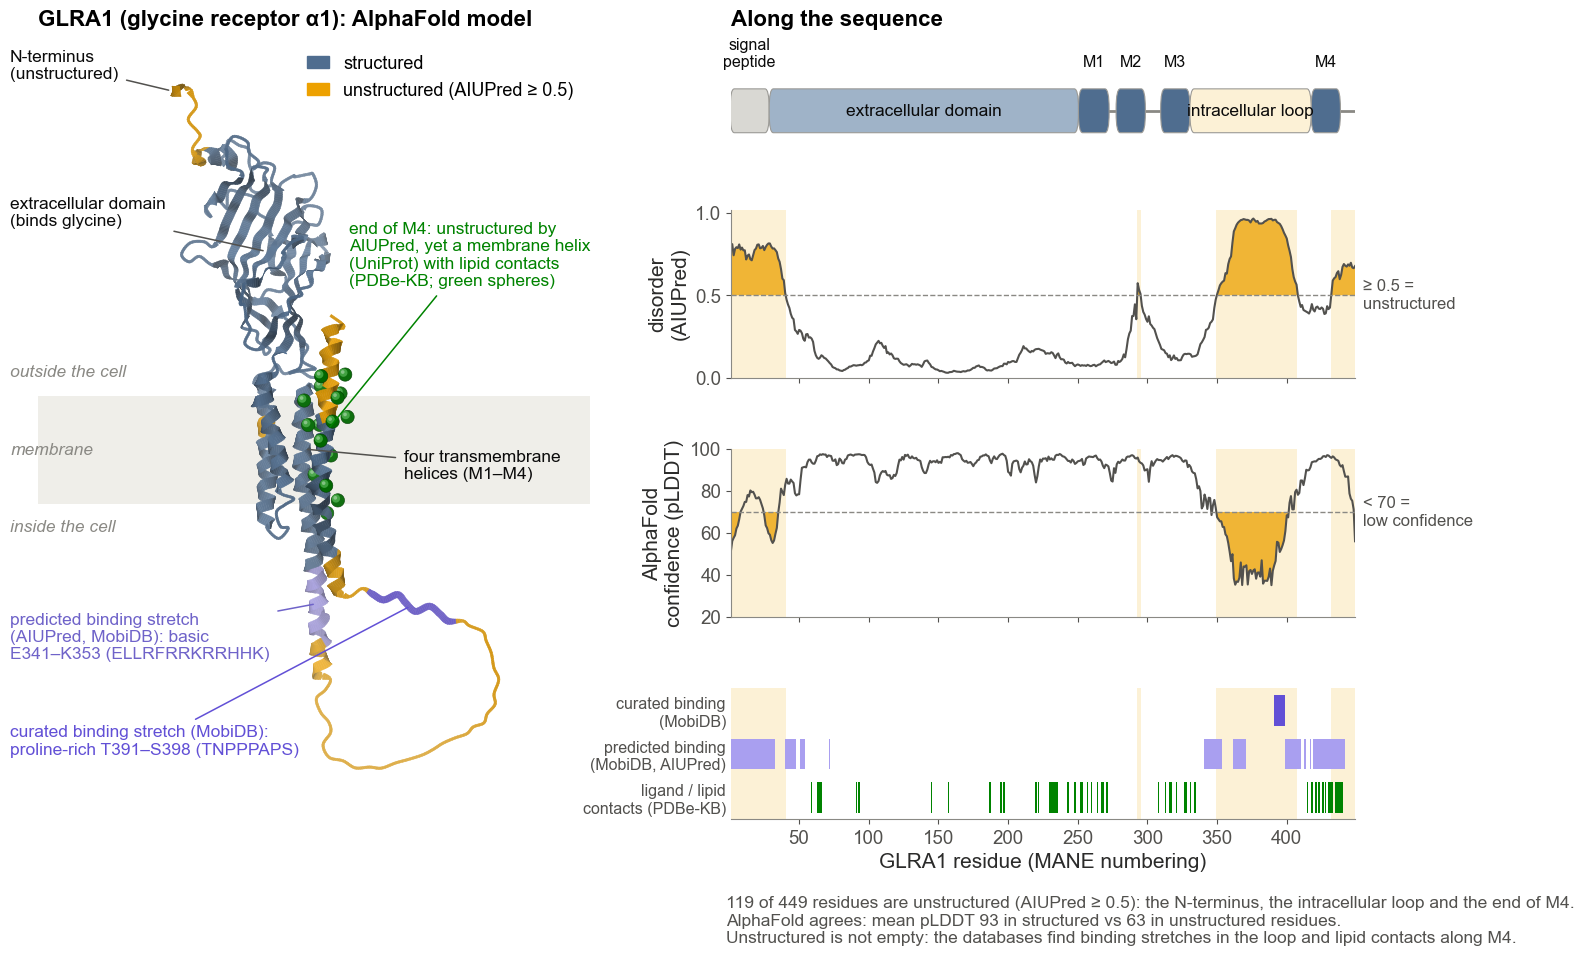

In [9]:
# M3a: GLRA1 overview, structured vs unstructured (AlphaFold model; colour = AIUPred, the model's definition),
# with examples of what the annotation databases find in the unstructured C-terminal half

def draw_structure_overview():
    '''M3a: the AlphaFold model, structured vs unstructured, annotation examples, sequence tracks.'''
    L = len(af)
    x = np.arange(1, L + 1)
    mature = x > 28                                                         # the signal peptide (1-28) is cleaved: not drawn
    ax_in = sum(sgn * (af.ca[e - 1] - af.ca[s - 1]) for (s, e), sgn in zip(TM, [1, -1, 1, -1]))
    up_af = -ax_in / np.linalg.norm(ax_in)                                  # membrane normal, pointing out of the cell
    front = np.cross(up_af, [1.0, 0.0, 0.0])
    R_af = rotate_about(view_matrix(up_af, front), "y", 60)

    # annotation examples (all from the model's own per-residue table)
    BIND_CUR, BIND_PRED, LIPID = VIOLET, "#a99ff0", GREEN
    flag = lambda col: gr[col].fillna(False).to_numpy().astype(bool)
    lip_cur = flag("ann_lip")                                               # MobiDB curated linear interacting peptide
    pred_bind = flag("ann_lip_predicted") | (gr.binding.to_numpy() >= 0.5)  # MobiDB predicted LIP or AIUPred binding >= 0.5
    ligand = flag("ann_ligand_site")                                        # PDBe-KB / UniProt ligand contacts
    basic = next((s0, e0) for s0, e0 in runs(pred_bind) if s0 > TM[2][1])    # first predicted binding stretch after M3
    pro = runs(lip_cur & (x > TM[2][1]))[0]                                 # the curated binding stretch in the loop
    in_rng = lambda rng: (x >= rng[0]) & (x <= rng[1])
    lipid_m4 = ligand & (x >= TM[3][0] - 3)                                 # lipid contacts on the end of M4
    seq_of = lambda rng: MANE_SEQ[rng[0] - 1:rng[1]]

    fig = plt.figure(figsize=(17, 10.2))
    gs = fig.add_gridspec(4, 2, width_ratios=[1.15, 1.3], height_ratios=[0.62, 1, 1, 0.78], wspace=0.24, hspace=0.5)
    ax3d = fig.add_subplot(gs[:, 0])
    sc = Scene(R_af, af.ca[mature].mean(0))
    colours = np.where(UNSTRUCT, UNSTRUCTURED, STRUCTURED).astype(object)
    colours[in_rng(basic)] = BIND_PRED; colours[in_rng(pro)] = BIND_CUR
    scale = np.where((in_rng(basic) | in_rng(pro)) & (np.array(list(af_ss)) == "C"), 2.6, 1.0)   # annotated loops drawn thicker
    sc.cartoon(af, af_ss, colours, keep=mature, scale=scale)
    sc.spheres(af.centroid()[lipid_m4], 1.7, [LIPID] * lipid_m4.sum())
    sc.draw(ax3d)
    ax3d.axis("off")
    x0, x1 = ax3d.get_xlim(); y0, y1 = ax3d.get_ylim()
    ax3d.set_xlim(x0 - 0.42 * (x1 - x0), x1 + 0.3 * (x1 - x0)); ax3d.set_ylim(y0 - 4, y1 + 4)
    y_tm = sc.project(np.vstack([af.ca[s - 1:e] for s, e in TM]))[:, 1]
    m_lo, m_hi = np.percentile(y_tm, [6, 94])
    ax3d.axhspan(m_lo, m_hi, color="#efeee9", lw=0, zorder=0)
    X0 = ax3d.get_xlim()[0]
    for yy, txt in [(m_hi + 6, "outside the cell"), ((m_lo + m_hi) / 2, "membrane"), (m_lo - 6, "inside the cell")]:
        ax3d.text(X0 + 2, yy, txt, fontsize=12.5, color=MUTED, va="center", style="italic")


    def callout(ax, xyz, text, xytext, ha="left", colour=INK, weight="normal"):
        xy = sc.project(xyz)[0]
        ax.annotate(text, xy, xytext, fontsize=12.5, color=colour, ha=ha, va="center", linespacing=1.2, weight=weight,
                    arrowprops=dict(arrowstyle="-", color=colour if colour != INK else INK2, lw=1.1, shrinkA=4, shrinkB=3))


    ecd = af.ca[(x > 40) & (x < TM[0][0])].mean(0)
    nterm = af.ca[29]
    y_top, y_bot = ax3d.get_ylim()[1], ax3d.get_ylim()[0]
    x_bundle = sc.project(af.ca[(x >= TM[0][0]) & (x <= TM[2][1])])[:, 0].max()
    callout(ax3d, ecd, "extracellular domain\n(binds glycine)", (X0 + 2, sc.project(ecd)[0][1] + 10))
    callout(ax3d, af.ca[(x >= TM[2][0]) & (x <= TM[2][1])].mean(0), "four transmembrane\nhelices (M1–M4)",
            (x_bundle + 22, (m_lo + m_hi) / 2 - 4))
    callout(ax3d, nterm, "N-terminus\n(unstructured)", (X0 + 2, y_top - 8))
    callout(ax3d, af.centroid()[lipid_m4].mean(0),
            "end of M4: unstructured by\nAIUPred, yet a membrane helix\n(UniProt) with lipid contacts\n(PDBe-KB; green spheres)",
            (x_bundle + 8, m_hi + 36), colour=LIPID)
    callout(ax3d, af.ca[in_rng(basic)].mean(0),
            f"predicted binding stretch\n(AIUPred, MobiDB): basic\n{MANE_SEQ[basic[0] - 1]}{basic[0]}–{MANE_SEQ[basic[1] - 1]}{basic[1]} ({seq_of(basic)})",
            (X0 + 2, m_lo - 34), colour="#6f63c9")
    callout(ax3d, af.ca[in_rng(pro)].mean(0),
            f"curated binding stretch (MobiDB):\nproline-rich {MANE_SEQ[pro[0] - 1]}{pro[0]}–{MANE_SEQ[pro[1] - 1]}{pro[1]} ({seq_of(pro)})",
            (X0 + 2, y_bot + 0.1 * (y_top - y_bot)), colour=BIND_CUR)
    ax3d.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=STRUCTURED, label="structured"),
                         plt.Rectangle((0, 0), 1, 1, color=UNSTRUCTURED, label="unstructured (AIUPred ≥ 0.5)")],
                frameon=False, loc="upper right", bbox_to_anchor=(1.0, 0.995), fontsize=13, handlelength=1.2)
    ax3d.set_title(f"{GENE} (glycine receptor α1): AlphaFold model", loc="left", fontsize=16)

    # ---- right: domain map, AIUPred disorder, AlphaFold confidence and the annotations along the sequence
    ax_dom = fig.add_subplot(gs[0, 1]); ax_dis = fig.add_subplot(gs[1, 1], sharex=ax_dom)
    ax_pl = fig.add_subplot(gs[2, 1], sharex=ax_dom); ax_ann = fig.add_subplot(gs[3, 1], sharex=ax_dom)
    loop_rng = (TM[2][1] + 1, TM[3][0] - 1)
    boxes = [((1, 28), "signal\npeptide", "#d9d8d3"), ((29, TM[0][0] - 1), "extracellular domain", "#9fb3c8")] + \
            [(rng, f"M{i + 1}", STRUCTURED) for i, rng in enumerate(TM)] + [(loop_rng, "intracellular loop", TINT[YELLOW])]
    ax_dom.plot([1, L], [0.5, 0.5], color=MUTED, lw=2, zorder=0)
    for (s0, e0), name, colr in boxes:
        ax_dom.add_patch(FancyBboxPatch((s0 - 0.5, 0.1), e0 - s0 + 1, 0.8, boxstyle="round,pad=0,rounding_size=3",
                                        mutation_aspect=0.12, fc=colr, ec="#9b9a96", lw=0.8))
        small = e0 - s0 < 40
        ax_dom.text((s0 + e0) / 2, 1.25 if small else 0.5, name, ha="center", va="bottom" if small else "center",
                    fontsize=11.5 if small else 12.5, color="white" if colr == STRUCTURED and not small else INK)
    ax_dom.set_ylim(0, 1.9); ax_dom.set_yticks([]); ax_dom.spines[["left", "bottom"]].set_visible(False)
    ax_dom.tick_params(axis="x", length=0, labelbottom=False)
    ax_dom.set_title("Along the sequence", loc="left", fontsize=16)
    dis = gr.disorder.to_numpy(); pl = gr.plddt.to_numpy()
    for a in (ax_dis, ax_pl, ax_ann):
        for s0, e0 in runs(UNSTRUCT):
            a.axvspan(s0 - 0.5, e0 + 0.5, color=TINT[YELLOW], lw=0, zorder=0)
    ax_dis.plot(x, dis, color=INK2, lw=1.5)
    ax_dis.fill_between(x, 0.5, dis, where=dis >= 0.5, color=YELLOW, alpha=0.75, lw=0, interpolate=True)
    ax_dis.axhline(0.5, color=MUTED, lw=1, ls="--")
    ax_dis.set_ylim(0, 1.02); ax_dis.set_ylabel("disorder\n(AIUPred)")
    ax_dis.text(L + 6, 0.5, "≥ 0.5 =\nunstructured", fontsize=12, color=INK2, va="center", clip_on=False)
    ax_pl.plot(x, pl, color=INK2, lw=1.5)
    ax_pl.fill_between(x, 70, pl, where=pl < 70, color=YELLOW, alpha=0.75, lw=0, interpolate=True)
    ax_pl.axhline(70, color=MUTED, lw=1, ls="--")
    ax_pl.set_ylim(20, 100); ax_pl.set_ylabel("AlphaFold\nconfidence (pLDDT)")
    ax_pl.text(L + 6, 70, "< 70 =\nlow confidence", fontsize=12, color=INK2, va="center", clip_on=False)
    rows = [(lip_cur, "curated binding\n(MobiDB)", BIND_CUR), (pred_bind, "predicted binding\n(MobiDB, AIUPred)", BIND_PRED),
            (ligand, "ligand / lipid\ncontacts (PDBe-KB)", LIPID)]
    for k, (m, name, colr) in enumerate(rows):
        ax_ann.bar(x[m], 0.7, bottom=len(rows) - 1 - k + 0.15, width=1.0, color=colr, lw=0)
    ax_ann.set_yticks([len(rows) - 1 - k + 0.5 for k in range(len(rows))], [r[1] for r in rows], fontsize=11.5)
    ax_ann.set_ylim(0, len(rows)); ax_ann.spines["left"].set_visible(False); ax_ann.tick_params(axis="y", length=0)
    ax_ann.set_xlabel(f"{GENE} residue (MANE numbering)"); ax_ann.set_xlim(1, L)
    for a in (ax_dis, ax_pl):
        a.tick_params(axis="x", labelbottom=False)
    n_un = int(UNSTRUCT.sum())
    fig.text(0.53, 0.035, f"{n_un} of {L} residues are unstructured (AIUPred ≥ 0.5): the N-terminus, the intracellular loop "
             f"and the end of M4.\nAlphaFold agrees: mean pLDDT {pl[~UNSTRUCT].mean():.0f} in structured vs "
             f"{pl[UNSTRUCT].mean():.0f} in unstructured residues.\nUnstructured is not empty: the databases find binding "
             f"stretches in the loop and lipid contacts along M4.", fontsize=12.5, color=INK2, va="top")
    save(fig, "M3a_glra1_structure_overview", dpi=300)


draw_structure_overview()

### 8b. Core and surface
`M3b_core_vs_surface.svg`

**What it shows.** A zoom into the extracellular domain of one α1 subunit (8DN5, chain A), at the height where glycine binds.
- **a:** subunit A from the side.
  - The grey band is the slice shown in b.
  - Orange marks the two glycines that subunit A helps to hold.
- **b:** a 14-Å-thick slice through the extracellular domain, seen from outside the cell, with one sphere per residue coloured by **burial**.
  - Burial is the **relative solvent accessibility (RSA)**: the share of a residue's surface that water could touch.
  - It is computed on the chain alone, exactly as for the model: Shrake–Rupley surface ÷ maximum surface (Tien et al. 2013).
  - Core < 0.2, boundary 0.2–0.4, surface > 0.4.
- **c:** the share of held-out ClinVar variants that are pathogenic in each class. These are labelled variants with ≥ 1 review star in all genes, never used to build any score (notebook 05 §6g).

**What to notice**
- **The extracellular domain is a β-sandwich:** two β-sheets packed face to face.
- **Core residues fill the space between the sheets and hold the fold together.** Changing one disturbs how the protein folds: 60% of held-out ClinVar variants at core residues are pathogenic (n = 547).
- **Surface residues face the water outside the cell and tolerate change:** 15% are pathogenic (n = 344).
- **Boundary residues** fall in between: 27% (n = 235).
- **Glycine binds at the subunit's edges,** where it meets its neighbours (next figure).

**Read with care.** "Surface" here means exposed *in a single chain*. In the assembled receptor, some surface residues touch the neighbouring subunits. Notebook 05 splits those out as **interface** residues (next figure), so the surface bar in c excludes them.

**Caption (copy-ready).** *Core and surface residues of GLRA1. (a) One α1 subunit (PDB 8DN5); grey band: slice shown in b; orange: bound glycine. (b) Cross-section through the extracellular β-sandwich at the glycine-binding level, coloured by relative solvent accessibility (RSA): core < 0.2, surface > 0.4. Core residues pack the two β-sheets together; surface residues face the solvent. (c) Share of held-out ClinVar variants that are pathogenic, by class: core 60%, boundary 27%, surface 15%.*

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


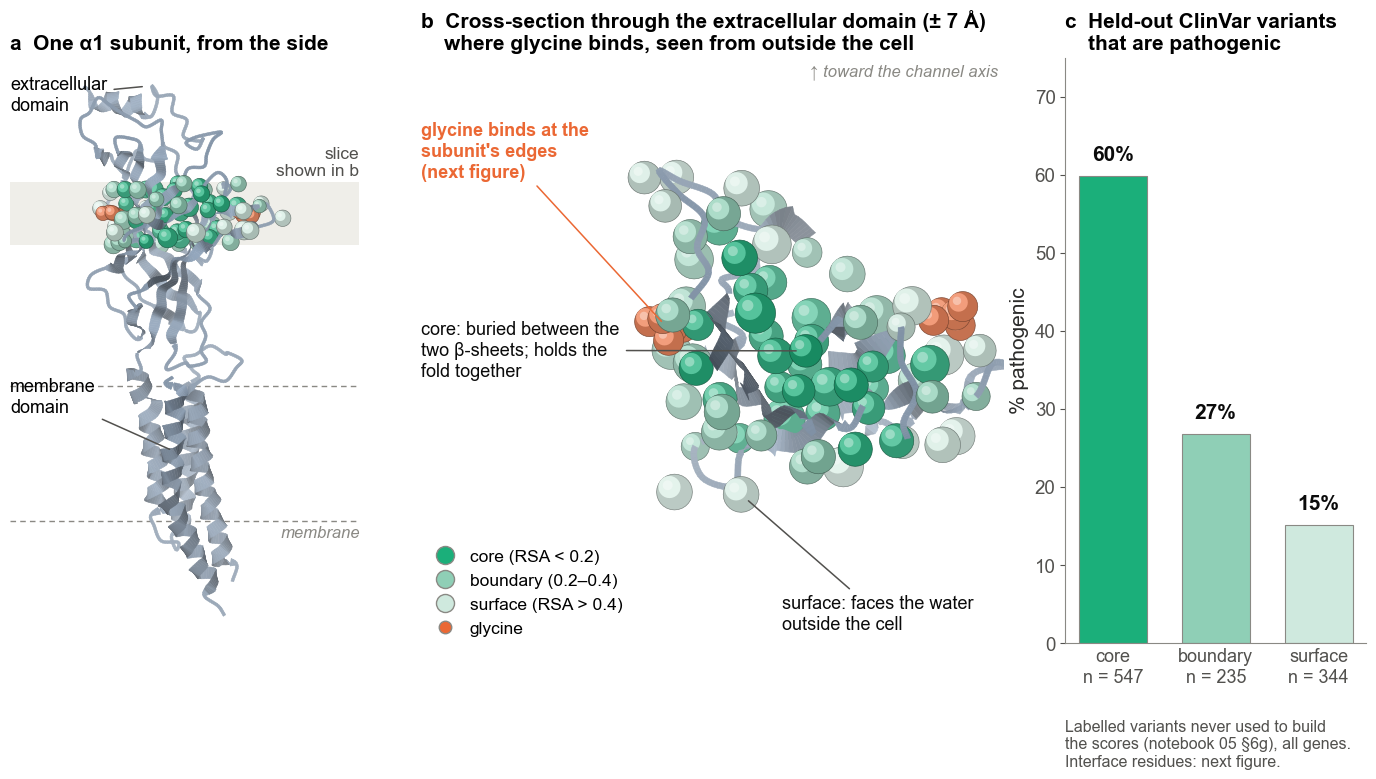

In [10]:
# M3b: core vs surface, in the extracellular domain of one a1 subunit, at the level where glycine binds (8DN5 chain A)

def draw_core_vs_surface():
    '''M3b: side view, extracellular cross-section and % pathogenic by burial class.'''
    RIBBON = "#8fa3ba"
    LEAD = dict(arrowstyle="-", color=INK2, lw=1.1, shrinkA=3, shrinkB=7)
    centA, rbA = A.centroid(), ball_radius(A)
    in_slab = (np.abs(height(centA)) < SLAB) & pd.notna(rsa_classA)
    slab_cols = [CLASS_COLOUR[c] for c in rsa_classA[in_slab]]
    gly_xyz = np.vstack([g["xyz"] for g in GLY_A])

    fig = plt.figure(figsize=(17.5, 7.6))
    gs = fig.add_gridspec(1, 3, width_ratios=[0.72, 1.2, 0.62], wspace=0.15)
    # ---- a: subunit A from the side, the slice marked
    ax = fig.add_subplot(gs[0])
    sc = Scene(view_matrix(UP, RAD), TMD_CENTRE)                            # seen from outside the receptor
    sc.cartoon(A, CH_SS["A"], [RIBBON] * len(A))
    sc.spheres(centA[in_slab], rbA[in_slab], slab_cols)
    sc.spheres(gly_xyz, 1.6, [GLYCINE_COLOUR] * len(gly_xyz))
    sc.draw(ax)
    ax.axis("off")
    ax.axhspan(GLY_H - SLAB, GLY_H + SLAB, color="#efeee9", lw=0, zorder=0)
    for yy in (-MEMBRANE, MEMBRANE):
        ax.axhline(yy, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
    ax.text(1.0, -MEMBRANE - 1, "membrane", transform=ax.get_yaxis_transform(), ha="right", va="top", fontsize=12, color=MUTED,
            style="italic")
    ax.text(1.0, GLY_H + SLAB + 0.8, "slice\nshown in b", transform=ax.get_yaxis_transform(), ha="right", va="bottom",
            fontsize=12.5, color=INK2)
    ecd = A.ca[(posA > 28) & (posA < 246)]
    ax.annotate("extracellular\ndomain", sc.project(ecd[np.argmax(height(ecd))])[0], (0.0, 0.97), textcoords="axes fraction",
                fontsize=13, va="top", arrowprops=LEAD)
    ax.annotate("membrane\ndomain", sc.project(A.ca[tm_maskA].mean(0))[0], (0.0, 0.42), textcoords="axes fraction",
                fontsize=13, va="center", arrowprops=LEAD)
    ax.set_title("a  One α1 subunit, from the side", loc="left", fontsize=15)

    # ---- b: the slice, seen from outside the cell
    ax = fig.add_subplot(gs[1])
    sc = Scene(view_matrix(-RAD, UP), centA[in_slab].mean(0))               # channel axis at the top
    sc.cartoon(A, CH_SS["A"], [RIBBON] * len(A), keep=np.abs(height(A.ca)) < SLAB + 1.5)
    sc.spheres(centA[in_slab], rbA[in_slab], slab_cols)
    sc.spheres(gly_xyz, 1.6, [GLYCINE_COLOUR] * len(gly_xyz))
    sc.draw(ax)
    ax.axis("off")
    xy_all = sc.project(centA[in_slab]); cx, cy = xy_all.mean(0)
    xl, yl = ax.get_xlim(), ax.get_ylim()
    ax.set_xlim(xl[0] - 46, xl[1] + 20); ax.set_ylim(yl[0] - 12, yl[1] + 9)
    cls_slab = rsa_classA[in_slab]
    core_xy = xy_all[cls_slab == "core"]; surf_xy = xy_all[cls_slab == "surface"]
    c_pt = core_xy[np.argmin(np.hypot(*(core_xy - [cx, cy]).T))]
    s_pt = surf_xy[np.argmin(surf_xy[:, 1])]
    ax.annotate("core: buried between the\ntwo β-sheets; holds the\nfold together", c_pt, (0.0, 0.5), textcoords="axes fraction",
                fontsize=13, color=INK, va="center", arrowprops=LEAD)
    ax.annotate("surface: faces the water\noutside the cell", s_pt, (0.62, 0.05), textcoords="axes fraction", fontsize=13,
                color=INK, va="center", arrowprops=LEAD)
    gly_left = min(GLY_A, key=lambda g: sc.project(g["xyz"].mean(0))[0][0])   # point at the glycine on the left
    ax.annotate("glycine binds at the\nsubunit's edges\n(next figure)", sc.project(gly_left["xyz"].mean(0))[0], (0.0, 0.84),
                textcoords="axes fraction", fontsize=13, color=GLYCINE_COLOUR, weight="bold", va="center",
                arrowprops=dict(arrowstyle="-", color=GLYCINE_COLOUR, lw=1.1, shrinkB=6))
    ax.text(0.99, 0.99, "↑ toward the channel axis", transform=ax.transAxes, fontsize=12, color=MUTED, style="italic",
            ha="right", va="top")
    ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=13, mfc=CLASS_COLOUR[c], mec="#8a8984", label=CLASS_LABEL[c])
                       for c in ["core", "boundary", "surface"]] +
              [plt.Line2D([], [], ls="", marker="o", ms=9, mfc=GLYCINE_COLOUR, mec="#8a8984", label="glycine")],
              frameon=False, loc="lower left", fontsize=12.5, handletextpad=0.4, borderaxespad=0)
    ax.set_title(f"b  Cross-section through the extracellular domain (± {SLAB:.0f} Å)\n"
                 "    where glycine binds, seen from outside the cell", loc="left", fontsize=15)

    # ---- c: how often is a held-out ClinVar variant pathogenic, by class?
    ax = fig.add_subplot(gs[2])
    order = ["core", "boundary", "surface"]
    pct = CLASS_TBL.loc[order, "pct_pathogenic"].to_numpy(); n = CLASS_TBL.loc[order, "n"].to_numpy()
    ax.bar(range(3), pct, color=[CLASS_COLOUR[c] for c in order], edgecolor="#8a8984", lw=0.8, width=0.66)
    for k, p_ in enumerate(pct):
        ax.text(k, p_ + 1.5, f"{p_:.0f}%", ha="center", va="bottom", fontsize=15, weight="bold", color=INK)
    ax.set_xticks(range(3), [f"{c}\nn = {n_:,}" for c, n_ in zip(order, n)], fontsize=13)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 75); ax.set_ylabel("% pathogenic")
    ax.set_title("c  Held-out ClinVar variants\n    that are pathogenic", loc="left", fontsize=15)
    ax.text(0.0, -0.13, "Labelled variants never used to build\nthe scores (notebook 05 §6g), all genes.\nInterface residues: next figure.",
            transform=ax.transAxes, fontsize=11.5, color=INK2, va="top")
    save(fig, "M3b_core_vs_surface", dpi=300)


draw_core_vs_surface()

### 8c. Interfaces: where glycine binds between subunits
`M3c_interfaces.svg`

**What it shows**
- **a: the whole receptor (8DN5) from the side.**
  - Subunit A is in front (slate), with its α1 neighbour (B, grey) and its β neighbour (E, light brown).
  - Orange marks the five bound glycines, one at each subunit interface.
  - The grey band is the slice; dashed lines mark the membrane.
- **b: the same slice as in the previous figure,** now with both neighbours.
  - **Violet:** residues of subunit A that are exposed (surface or boundary) *and* touch a neighbour (any atom within 4.5 Å).
  - **Pale violet:** the neighbour's side of the same contact.
  - **Orange:** glycine.
- **c: the held-out ClinVar comparison again,** now with interface residues as their own class, plus residues annotated as ligand-binding sites.

**What to notice**
- **Glycine binds between two subunits.** Each pocket is built from loops of both (residues within 4 Å of glycine in 8DN5):
  - **Between A and its α1 neighbour:** F187, Y230 and F235 of subunit A (its "principal" face), and F91, R93 and S157 of the neighbour (its "complementary" face).
  - **Between A and the β neighbour:** F91, R93 and S157 of subunit A, and the β subunit's principal face.
  - In the mature-protein numbering used in most papers, subtract 28: F159, Y202, F207, F63, R65, S129.
- **Interface residues are exposed, yet as constrained as the core.** 68% of held-out ClinVar variants there are pathogenic (n = 174), against 15% for other surface residues. A substitution at an interface can break the contact between subunits, or the glycine pocket itself, without disturbing the fold.
- **Ligand-binding residues are the most constrained of all:** 86% of held-out ClinVar variants there are pathogenic (n = 99, all genes).
- **The final model learned the same thing:** its weights push exposed residues toward benign (+0.44) but interface residues toward pathogenic (−0.49) (Results 4b).

**Where these features come from**
- **The figure finds contacts directly in 8DN5:** 105 residues of subunit A touch subunit B or E.
- **The model's interface feature comes from PDBe-KB,** which collects contacts from every PDB entry of the protein. It flags 101 of these 105, plus contacts seen in other structures, some with engineered partners (GFP fused into the β subunit, and a GLIC chimera, 4X5T; notebook 05 §7d).
- **The ligand-site feature (PDBe-KB and UniProt) is broader than "ligands".** It also counts contacts with sugars (NAG) and with lipid-like chains modelled into cryo-EM maps. In GLRA1, most ligand sites in the membrane domain are such lipid contacts.

**Caption (copy-ready).** *Glycine binds at interfaces between subunits. (a) The human α1β glycine receptor with glycine bound (orange; PDB 8DN5); subunit A in slate, its α1 and β neighbours in grey and brown. (b) Cross-section through the extracellular domain: exposed residues of subunit A that touch a neighbour (violet) face the neighbours' matching surfaces (pale violet); each glycine pocket is formed by both subunits. (c) Held-out ClinVar variants that are pathogenic: ligand-binding residues 86%, interface 68%, core 60%, other surface 15%.*

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


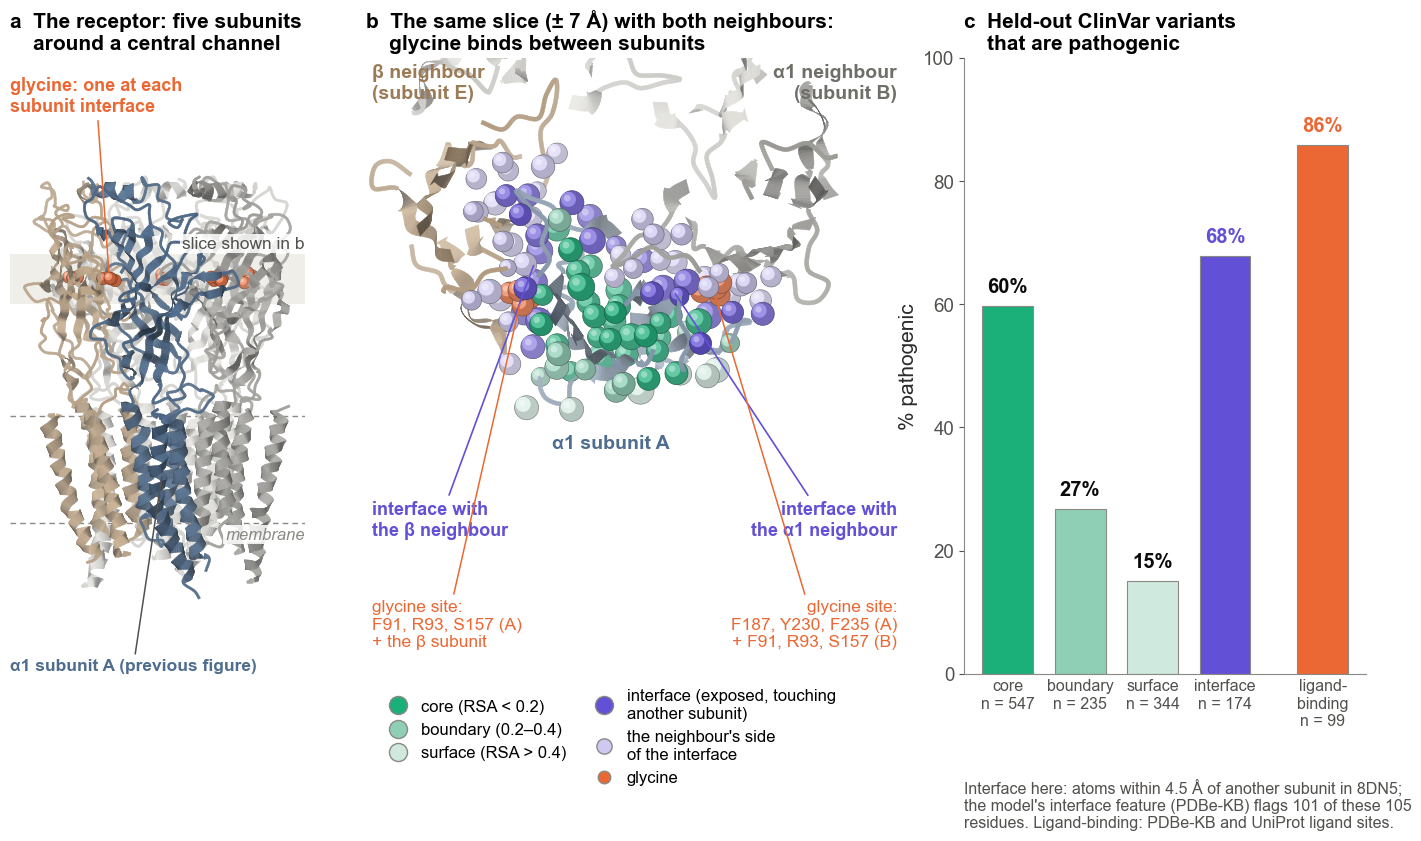

In [11]:
# M3c: the interfaces where glycine binds: the same extracellular slice, widened to the two neighbouring subunits (8DN5)

def draw_interfaces():
    '''M3c: the receptor with glycine, the widened cross-section, % pathogenic incl. interfaces and ligand sites.'''
    SUBUNIT = {"A": "α1", "B": "α1", "C": "α1", "D": "α1", "E": "β"}
    CHAIN_COLOUR = {"A": STRUCTURED, "B": "#a9a8a3", "C": "#e3e2dd", "D": "#e3e2dd", "E": "#c4a988"}   # E = the beta subunit
    NAME_COLOUR = {"B": "#6f6e69", "E": "#9a7b55"}
    centA, rbA = A.centroid(), ball_radius(A)
    in_slabA = (np.abs(height(centA)) < SLAB) & pd.notna(classA)
    all_gly = np.vstack([g["xyz"] for g in GLYCINES])

    fig = plt.figure(figsize=(17.5, 8.0))
    gs = fig.add_gridspec(1, 3, width_ratios=[0.66, 1.2, 0.9], wspace=0.15)
    # ---- a: the whole receptor from the side, chain A in front, glycine in orange
    ax = fig.add_subplot(gs[0])
    sc = Scene(view_matrix(UP, RAD), TMD_CENTRE)
    for k in "ABCDE":
        sc.cartoon(CH[k], CH_SS[k], [CHAIN_COLOUR[k]] * len(CH[k]))
    sc.spheres(all_gly, 1.7, [GLYCINE_COLOUR] * len(all_gly))
    sc.draw(ax)
    ax.axis("off")
    ax.axhspan(GLY_H - SLAB, GLY_H + SLAB, color="#efeee9", lw=0, zorder=0)
    for yy in (-MEMBRANE, MEMBRANE):
        ax.axhline(yy, color=MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
    yl = ax.get_ylim(); ax.set_ylim(yl[0] - 6, yl[1] + 18)
    ax.text(1.0, -MEMBRANE - 1, "membrane", transform=ax.get_yaxis_transform(), ha="right", va="top", fontsize=12, color=MUTED,
            style="italic", bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
    ax.text(1.0, GLY_H + SLAB + 0.8, "slice shown in b", transform=ax.get_yaxis_transform(), ha="right", va="bottom",
            fontsize=12.5, color=INK2, bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
    front_gly = max(GLYCINES, key=lambda g: sc.to_view(g["xyz"].mean(0)[None])[0, 2])   # the glycine nearest the viewer
    ax.annotate("glycine: one at each\nsubunit interface", sc.project(front_gly["xyz"].mean(0))[0], (0.0, 0.97),
                textcoords="axes fraction", fontsize=13, color=GLYCINE_COLOUR, weight="bold", va="top",
                arrowprops=dict(arrowstyle="-", color=GLYCINE_COLOUR, lw=1.1, shrinkB=5))
    ax.annotate("α1 subunit A (previous figure)", sc.project(A.ca[tm_maskA].mean(0))[0], (0.0, 0.0), textcoords="axes fraction",
                fontsize=12.5, color=STRUCTURED, weight="bold", va="bottom", arrowprops=dict(arrowstyle="-", color=INK2, lw=1.1, shrinkB=5),
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.5))
    ax.set_title("a  The receptor: five subunits\n    around a central channel", loc="left", fontsize=15)

    # ---- b: the slice where glycine binds, with subunit A's two neighbours (channel axis at the top)
    ax = fig.add_subplot(gs[1])
    sc = Scene(view_matrix(-RAD, UP), SLICE_CENTRE)
    for k in "ABCDE":
        r = CH[k]
        sc.cartoon(r, CH_SS[k], [("#8fa3ba" if k == "A" else CHAIN_COLOUR[k])] * len(r), keep=np.abs(height(r.ca)) < SLAB + 1.5)
        if k in NEIGHBOURS:                                                 # the neighbour's side of each interface
            ck = r.centroid()
            m = (np.abs(height(ck)) < SLAB) & np.isin(r.num, list(touched[k]))
            sc.spheres(ck[m], ball_radius(r)[m] * 0.9, ["#cfc9f2"] * m.sum())
    sc.spheres(centA[in_slabA], rbA[in_slabA], [CLASS_COLOUR[c] for c in classA[in_slabA]])
    for g in GLY_A:                                                         # the two glycines subunit A helps to hold
        sc.spheres(g["xyz"], 1.7, [GLYCINE_COLOUR] * len(g["xyz"]))
    sc.draw(ax)
    ax.axis("off")
    xyA = sc.project(centA[in_slabA]); xyA0 = xyA.mean(0)
    ax.set_xlim(xyA[:, 0].min() - 22, xyA[:, 0].max() + 22)
    ax.set_ylim(xyA[:, 1].min() - 36, xyA[:, 1].max() + 16)
    ax.text(xyA0[0], xyA[:, 1].min() - 4, "α1 subunit A", ha="center", va="top", fontsize=14, weight="bold", color=STRUCTURED)
    for k in NEIGHBOURS:
        side = np.sign(sc.project(CH[k].ca.mean(0))[0][0] - xyA0[0])      # -1: left, +1: right
        x_txt, ha = (0.01, "left") if side < 0 else (0.99, "right")
        ax.text(x_txt, 0.99, f"{SUBUNIT[k]} neighbour\n(subunit {k})", transform=ax.transAxes, ha=ha, va="top", fontsize=14,
                weight="bold", color=NAME_COLOUR[k])
        pts = xyA[(classA[in_slabA] == "interface") & np.array([k in p for p in partnerA[in_slabA]])]
        ax.annotate(f"interface with\nthe {SUBUNIT[k]} neighbour", pts.mean(0), (x_txt, 0.25), textcoords="axes fraction",
                    fontsize=13, color=VIOLET, weight="bold", va="center", ha=ha,
                    arrowprops=dict(arrowstyle="-", color=VIOLET, lw=1.2, shrinkB=8))
        g = next(g for g in GLY_A if k in g["site"])
        resA = ", ".join(label_of("A", n) for n in sorted(g["site"]["A"]))
        other = (", ".join(label_of(k, n) for n in sorted(g["site"][k])) + f" ({k})") if k in POS else "the β subunit"
        ax.annotate(f"glycine site:\n{resA} (A)\n+ {other}", sc.project(g["xyz"].mean(0))[0], (x_txt, 0.08),
                    textcoords="axes fraction", fontsize=12.5, color=GLYCINE_COLOUR, va="center", ha=ha,
                    arrowprops=dict(arrowstyle="-", color=GLYCINE_COLOUR, lw=1.1, shrinkB=6))
    ax.legend(handles=[plt.Line2D([], [], ls="", marker="o", ms=13, mfc=CLASS_COLOUR[c], mec="#8a8984", label=CLASS_LABEL[c])
                       for c in ["core", "boundary", "surface", "interface"]] +
              [plt.Line2D([], [], ls="", marker="o", ms=11, mfc="#cfc9f2", mec="#8a8984", label="the neighbour's side\nof the interface"),
               plt.Line2D([], [], ls="", marker="o", ms=9, mfc=GLYCINE_COLOUR, mec="#8a8984", label="glycine")],
              frameon=False, loc="upper left", bbox_to_anchor=(0.0, 0.0), fontsize=12, handletextpad=0.4, ncol=2,
              columnspacing=1.2)
    ax.set_title(f"b  The same slice (± {SLAB:.0f} Å) with both neighbours:\n    glycine binds between subunits", loc="left", fontsize=15)

    # ---- c: interface and ligand-binding residues are exposed, yet as constrained as the core
    ax = fig.add_subplot(gs[2])
    order = ["core", "boundary", "surface", "interface", "ligand site"]
    xpos = [0, 1, 2, 3, 4.35]
    colours = [CLASS_COLOUR[c] for c in order[:4]] + [GLYCINE_COLOUR]
    pct = CLASS_TBL.loc[order, "pct_pathogenic"].to_numpy(); n = CLASS_TBL.loc[order, "n"].to_numpy()
    ax.bar(xpos, pct, color=colours, edgecolor="#8a8984", lw=0.8, width=0.7)
    for x_, c, p_ in zip(xpos, order, pct):
        ax.text(x_, p_ + 1.5, f"{p_:.0f}%", ha="center", va="bottom", fontsize=14.5, weight="bold",
                color={"interface": VIOLET, "ligand site": GLYCINE_COLOUR}.get(c, INK))
    ax.set_xticks(xpos, [f"{c.replace('ligand site', 'ligand-')}\n{'binding' if c == 'ligand site' else ''}\nn = {n_:,}".replace("\n\n", "\n")
                         for c, n_ in zip(order, n)], fontsize=11.5)
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 100); ax.set_ylabel("% pathogenic")
    ax.set_title("c  Held-out ClinVar variants\n    that are pathogenic", loc="left", fontsize=15)
    ax.text(0.0, -0.17, f"Interface here: atoms within 4.5 Å of another subunit in 8DN5;\nthe model's interface feature (PDBe-KB) flags "
            f"{kb_ifaceA[contactA].sum()} of these {contactA.sum()}\nresidues. Ligand-binding: PDBe-KB and UniProt ligand sites.",
            transform=ax.transAxes, fontsize=11.5, color=INK2, va="top")
    save(fig, "M3c_interfaces", dpi=300)


draw_interfaces()

### 8d. Every structural feature along the sequence
`M3_structural_feature_tracks.svg`

Every track is one column of `residue_df` (notebook 05 §5, §7, §8), all aligned on the same MANE residue numbering:

| Track | Source | Meaning |
|---|---|---|
| tolerance | 05 §3 | the score from Methods 1, centred on the gene's median |
| disorder, binding | AIUPred | disorder ≥ 0.5 = disordered (unstructured); binding = predicted binding regions within disorder |
| RSA | PDB first, AlphaFold otherwise | relative solvent accessibility: share of the residue's surface exposed to water. Core < 0.2, boundary 0.2–0.4, surface > 0.4. Left empty where AlphaFold's confidence (pLDDT) is below 70, mostly in disordered regions |
| interface | PDBe-KB | the residue contacts another protein chain in an experimental structure |
| annotations | InterPro, UniProt, MobiDB, ELM, PDBe-KB | domains, signal peptide, transmembrane segments, ligand-binding sites, disulfides, PTM sites, motifs |

The dotted line marks p.A300P, which sits in an exposed region of the second transmembrane segment, close to ligand sites and an interface.

**Caption (copy-ready).** *Per-residue structural context of GLRA1: tolerance, AIUPred disorder and binding, relative solvent accessibility (core < 0.2 < boundary < 0.4 < surface), protein–protein interfaces (PDBe-KB) and annotated features (InterPro, UniProt, MobiDB, ELM). Dotted line: p.A300P.*

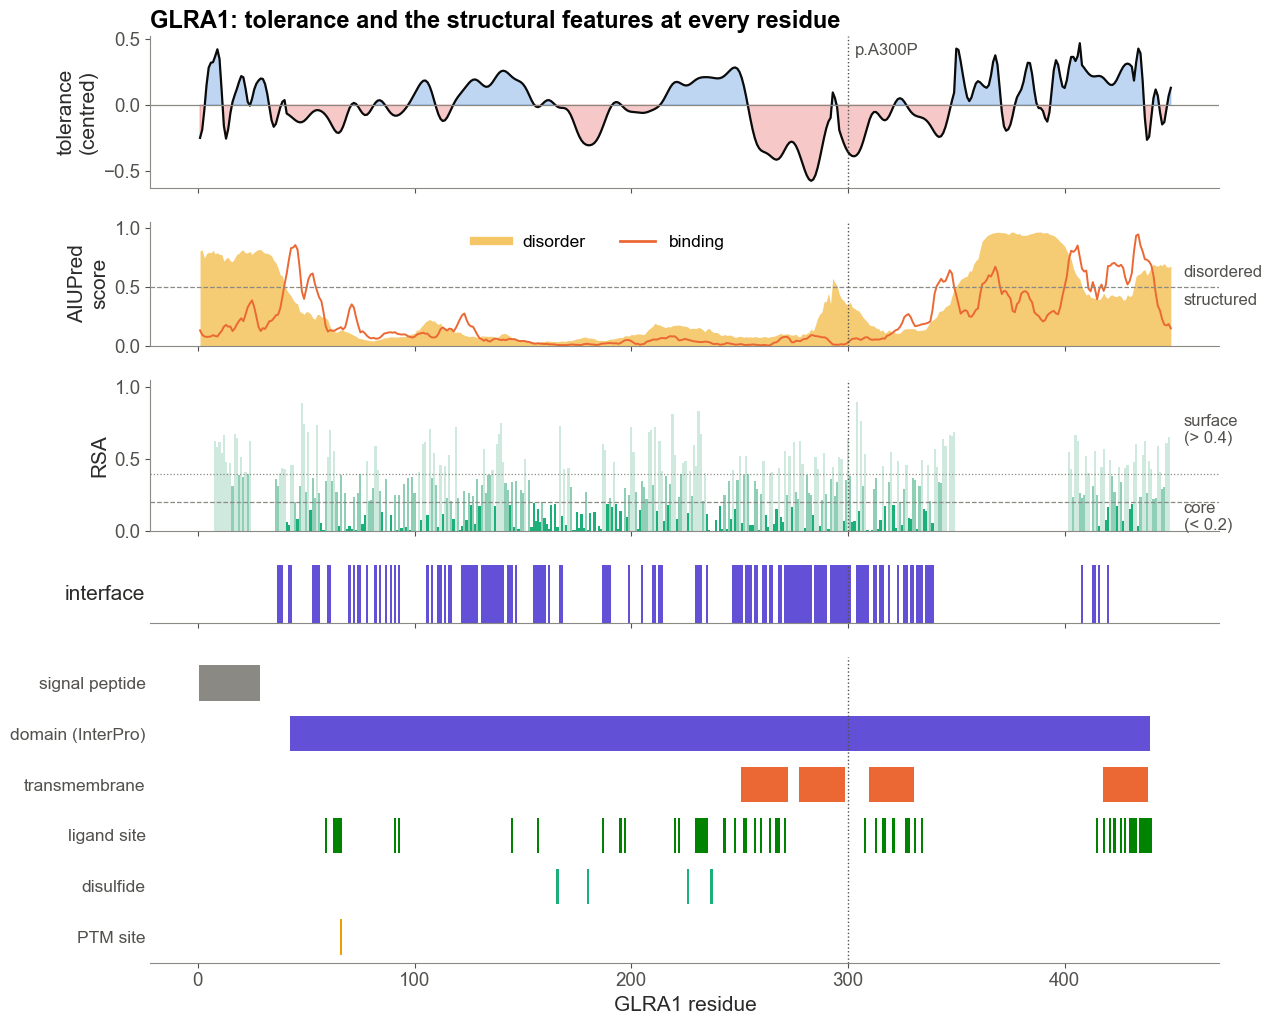

residue 300: RSA 0.64, interface True, disorder 0.34, transmembrane False | RSA available for 84% of GLRA1's residues


In [12]:
rg = residue_df[residue_df.gene == GENE].sort_values("pos").reset_index(drop=True)
pos = rg.pos.to_numpy()
tracks = [("ann_signal", "signal peptide", MUTED), ("ann_domain", "domain (InterPro)", VIOLET),
          ("ann_transmembrane", "transmembrane", ORANGE), ("ann_ligand_site", "ligand site", GREEN),
          ("ann_disulfide", "disulfide", AQUA), ("ann_ptm", "PTM site", YELLOW),
          ("ann_motif", "motif", RED), ("ann_motif_predicted", "predicted motif", RED)]
tracks = [tr for tr in tracks if tr[0] in rg and rg[tr[0]].fillna(False).astype(bool).any()]   # only those present

fig, axes = plt.subplots(5, 1, figsize=(13, 10.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.1, 0.9, 1.1, 0.42, 0.32 * len(tracks) + 0.3]})
ax = axes[0]
tc = rg.tolerance_v4_centered.to_numpy()
ax.plot(pos, tc, color=INK, lw=1.6)
ax.fill_between(pos, tc, 0, where=tc > 0, color=BLUE, alpha=0.3, interpolate=True)
ax.fill_between(pos, tc, 0, where=tc < 0, color=RED, alpha=0.3, interpolate=True)
ax.axhline(0, color=MUTED, lw=0.9); ax.set_ylabel("tolerance\n(centred)")
ax.set_title(f"{GENE}: tolerance and the structural features at every residue")
ax = axes[1]
ax.fill_between(pos, rg.disorder.to_numpy(), color=YELLOW, alpha=0.55, lw=0)
ax.plot(pos, rg.binding.to_numpy(), color=ORANGE, lw=1.4)
ax.axhline(0.5, color=MUTED, lw=0.9, ls="--")
ax.text(pos[-1] + 6, 0.62, "disordered", ha="left", va="center", fontsize=12, color=INK2, clip_on=False)
ax.text(pos[-1] + 6, 0.38, "structured", ha="left", va="center", fontsize=12, color=INK2, clip_on=False)
ax.set_ylim(0, 1.05); ax.set_ylabel("AIUPred\nscore")
ax.legend(handles=[Line2D([], [], color=YELLOW, lw=6, alpha=0.6, label="disorder"),
                   Line2D([], [], color=ORANGE, lw=2, label="binding")], frameon=False, ncol=2, loc="upper center",
          bbox_to_anchor=(0.42, 1.02), fontsize=12.5)
ax = axes[2]
rsa = rg.rsa.to_numpy(dtype=float); ok_ = np.isfinite(rsa)
shade = np.where(rsa < 0.2, AQUA, np.where(rsa <= 0.4, "#8fcfb6", "#cfe9de"))       # core / boundary / surface
ax.bar(pos[ok_], rsa[ok_], width=1.0, color=shade[ok_], lw=0)
ax.axhline(0.2, color=MUTED, lw=0.9, ls="--"); ax.axhline(0.4, color=MUTED, lw=0.9, ls=":")
ax.set_ylim(0, 1.05); ax.set_ylabel("RSA")
ax.text(pos[-1] + 6, 0.7, "surface\n(> 0.4)", ha="left", va="center", fontsize=12, color=INK2, clip_on=False)
ax.text(pos[-1] + 6, 0.1, "core\n(< 0.2)", ha="left", va="center", fontsize=12, color=INK2, clip_on=False)
ax = axes[3]
iface = rg.iface_any.fillna(False).astype(bool).to_numpy()
ax.bar(pos[iface], 1, width=1.0, color=VIOLET, lw=0)
ax.set_yticks([]); ax.set_ylim(0, 1); ax.set_ylabel("interface", rotation=0, ha="right", va="center")
ax.spines["left"].set_visible(False)
ax = axes[4]
for k, (col, labl, colr) in enumerate(tracks):
    m = rg[col].fillna(False).astype(bool).to_numpy()
    ax.bar(pos[m], 0.7, bottom=len(tracks) - 1 - k + 0.15, width=1.0, color=colr, lw=0)
ax.set_yticks([len(tracks) - 1 - k + 0.5 for k in range(len(tracks))], [labl for _, labl, _ in tracks], fontsize=12.5)
ax.set_ylim(0, len(tracks)); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel(f"{GENE} residue")
for a in axes:
    a.axvline(VAR_POS, color=INK2, lw=1, ls=":")
axes[0].text(VAR_POS + 3, axes[0].get_ylim()[1] * 0.9, f"p.A{VAR_POS}P", fontsize=12, color=INK2, va="top")
fig.tight_layout(); save(fig, "M3_structural_feature_tracks")
r300 = rg.set_index("pos").loc[VAR_POS]
print(f"residue {VAR_POS}: RSA {r300.rsa:.2f}, interface {bool(r300.iface_any)}, disorder {r300.disorder:.2f}, "
      f"transmembrane {bool(r300.ann_transmembrane)} | RSA available for {np.isfinite(rsa).mean():.0%} of {GENE}'s residues")

### 8e. Where the domain, motif and interaction-site annotations come from
`M3d_annotation_sources.svg`

**How the annotations were pulled** (notebook 05 §7–§8)
1. **Fetch.** One request per UniProt accession to each database, cached as one JSON file per protein: InterPro, UniProt, MobiDB, ELM, PDBe-KB, PDBe and AlphaFold DB. AIUPred scores were computed for every MANE sequence and stored with the sequences (05 §2).
2. **Normalise.** Every feature becomes one row: protein, source, category, name, start, end. That gives `annotations_long.parquet`, about 118,000 rows. Categories come from a fixed list:
   - domain, repeat, motif, binding region, linear interacting peptide (LIP);
   - modification (PTM) site, disulfide, ligand site, active site, conserved site;
   - coiled coil, transmembrane segment, signal peptide, curated disorder.
3. **Map.** UniProt positions are mapped onto the MANE sequence by sequence alignment. Some genes' MANE transcript is a different UniProt isoform, as for GLRA1.
4. **Expand.** Each category becomes one yes/no column per residue, `ann_<category>`, plus `n_annotations`: how many curated categories mark the residue.
5. **Exclude.** UniProt natural variants and mutagenesis results are left out. They come from disease variants and would leak ClinVar-like information into the features.

The figure lists, for each database:
- what it looks for;
- what that means for the protein;
- which model features it feeds;
- what it finds in GLRA1.

**Caption (copy-ready).** *Sources of the structural and annotation features. Each database is queried per protein, mapped onto the MANE sequence and expanded to one value per residue; UniProt natural-variant and mutagenesis records are excluded to avoid leaking clinical labels.*

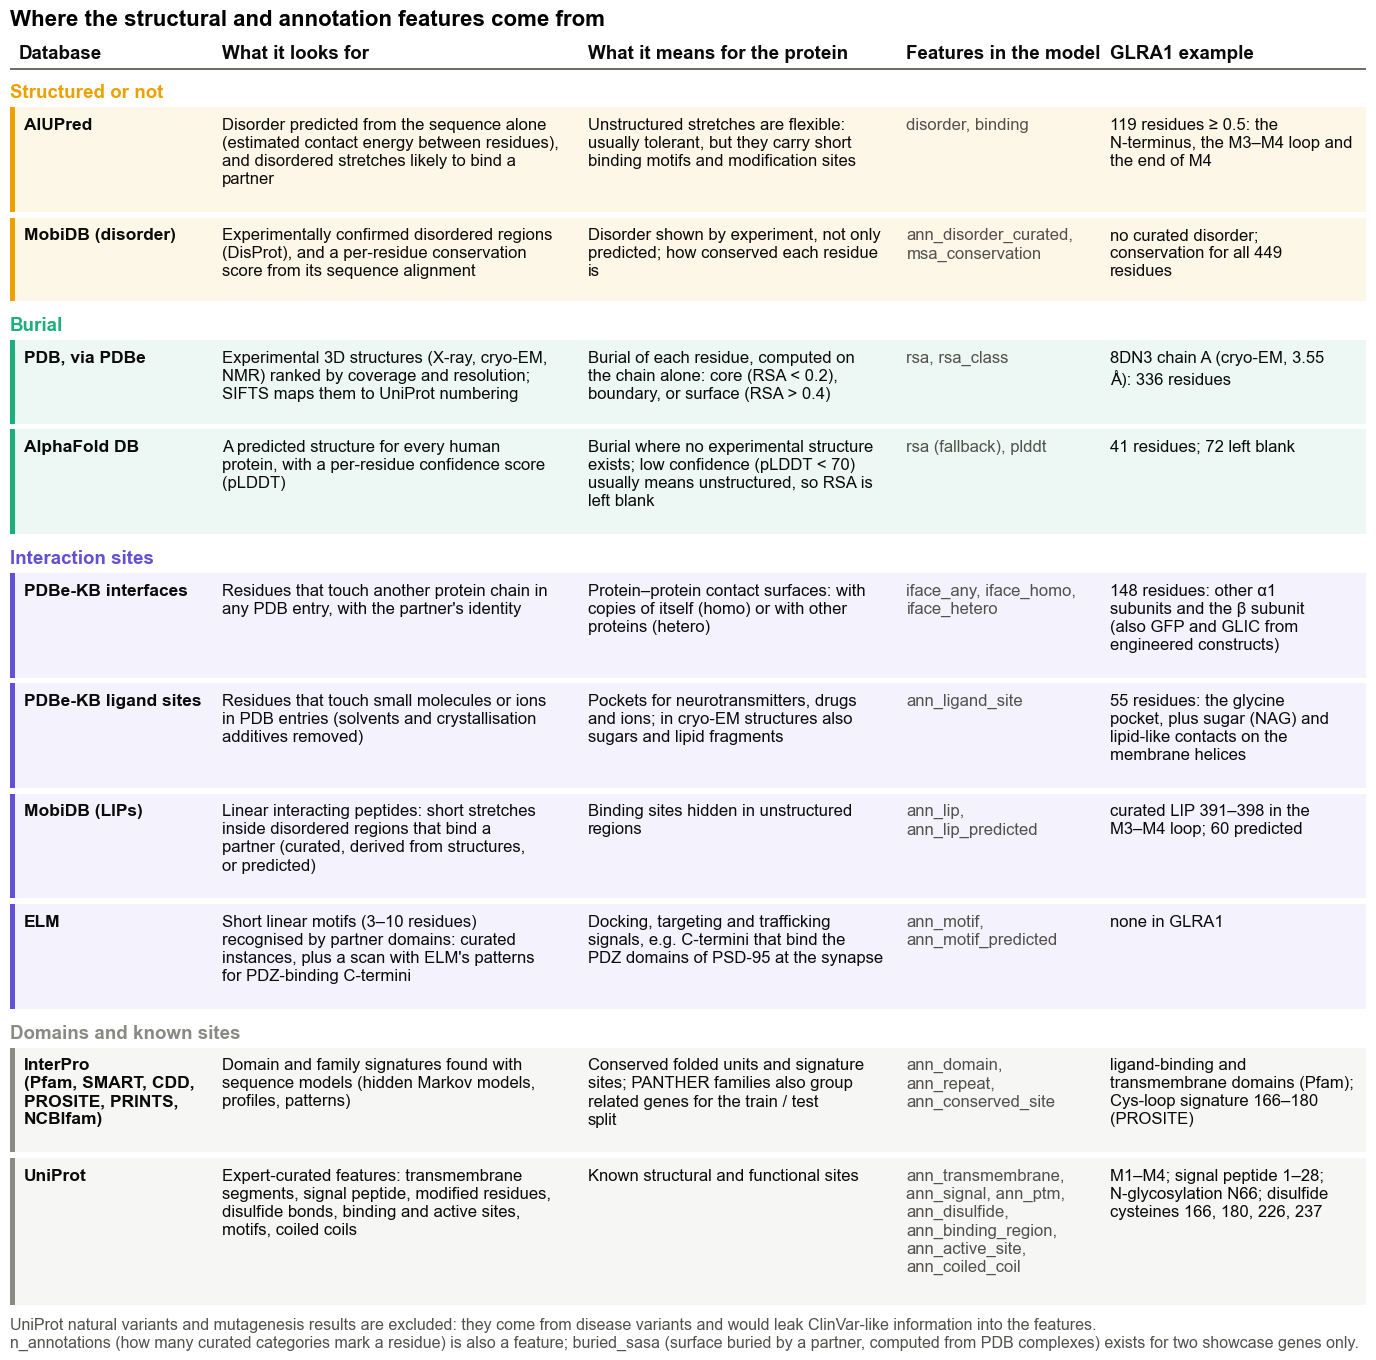

In [13]:
# M3d: where the structural and annotation features come from (a table drawn as a figure: every word is editable text)

def draw_annotation_sources():
    '''M3d: the databases behind the structural and annotation features, as a table.'''
    import textwrap


    def ranges_text(col, sep=", "):
        '''MANE ranges of GLRA1 residues flagged in a residue_df column, e.g. "166–180, 226".'''
        return sep.join(f"{a}" if a == b else f"{a}–{b}" for a, b in runs(gr[col].fillna(False).to_numpy()))


    n_flag = lambda col: int(gr[col].fillna(False).astype(bool).sum())
    src = gr.rsa_source.fillna("none")
    GROUPS = {"Structured or not": YELLOW, "Burial": AQUA, "Interaction sites": VIOLET, "Domains and known sites": MUTED}
    ROWS = [  # group, database, what it looks for, what it means for the protein, model features, GLRA1 example
        ("Structured or not", "AIUPred",
         "Disorder predicted from the sequence alone (estimated contact energy between residues), and disordered stretches likely to bind a partner",
         "Unstructured stretches are flexible: usually tolerant, but they carry short binding motifs and modification sites",
         "disorder, binding", f"{int(UNSTRUCT.sum())} residues ≥ 0.5: the N-terminus, the M3–M4 loop and the end of M4"),
        ("Structured or not", "MobiDB (disorder)",
         "Experimentally confirmed disordered regions (DisProt), and a per-residue conservation score from its sequence alignment",
         "Disorder shown by experiment, not only predicted; how conserved each residue is",
         "ann_disorder_curated, msa_conservation", f"no curated disorder; conservation for all {len(gr)} residues"),
        ("Burial", "PDB, via PDBe",
         "Experimental 3D structures (X-ray, cryo-EM, NMR) ranked by coverage and resolution; SIFTS maps them to UniProt numbering",
         "Burial of each residue, computed on the chain alone: core (RSA < 0.2), boundary, or surface (RSA > 0.4)",
         "rsa, rsa_class", f"8DN3 chain A (cryo-EM, 3.55 Å): {int((src == 'pdb:8dn3_A').sum())} residues"),
        ("Burial", "AlphaFold DB",
         "A predicted structure for every human protein, with a per-residue confidence score (pLDDT)",
         "Burial where no experimental structure exists; low confidence (pLDDT < 70) usually means unstructured, so RSA is left blank",
         "rsa (fallback), plddt", f"{int((src == 'alphafold').sum())} residues; {int((src == 'none').sum())} left blank"),
        ("Interaction sites", "PDBe-KB interfaces",
         "Residues that touch another protein chain in any PDB entry, with the partner's identity",
         "Protein–protein contact surfaces: with copies of itself (homo) or with other proteins (hetero)",
         "iface_any, iface_homo, iface_hetero",
         f"{n_flag('iface_any')} residues: other α1 subunits and the β subunit (also GFP and GLIC from engineered constructs)"),
        ("Interaction sites", "PDBe-KB ligand sites",
         "Residues that touch small molecules or ions in PDB entries (solvents and crystallisation additives removed)",
         "Pockets for neurotransmitters, drugs and ions; in cryo-EM structures also sugars and lipid fragments", "ann_ligand_site",
         f"{n_flag('ann_ligand_site')} residues: the glycine pocket, plus sugar (NAG) and lipid-like contacts on the membrane helices"),
        ("Interaction sites", "MobiDB (LIPs)",
         "Linear interacting peptides: short stretches inside disordered regions that bind a partner (curated, derived from structures, or predicted)",
         "Binding sites hidden in unstructured regions", "ann_lip, ann_lip_predicted",
         f"curated LIP {ranges_text('ann_lip')} in the M3–M4 loop; {n_flag('ann_lip_predicted')} predicted"),
        ("Interaction sites", "ELM",
         "Short linear motifs (3–10 residues) recognised by partner domains: curated instances, plus a scan with ELM's patterns for PDZ-binding C-termini",
         "Docking, targeting and trafficking signals, e.g. C-termini that bind the PDZ domains of PSD-95 at the synapse",
         "ann_motif, ann_motif_predicted", "none in GLRA1"),
        ("Domains and known sites", "InterPro\n(Pfam, SMART, CDD, PROSITE, PRINTS, NCBIfam)",
         "Domain and family signatures found with sequence models (hidden Markov models, profiles, patterns)",
         "Conserved folded units and signature sites; PANTHER families also group related genes for the train / test split",
         "ann_domain, ann_repeat, ann_conserved_site",
         f"ligand-binding and transmembrane domains (Pfam); Cys-loop signature {ranges_text('ann_conserved_site')} (PROSITE)"),
        ("Domains and known sites", "UniProt",
         "Expert-curated features: transmembrane segments, signal peptide, modified residues, disulfide bonds, binding and active sites, motifs, coiled coils",
         "Known structural and functional sites",
         "ann_transmembrane, ann_signal, ann_ptm, ann_disulfide, ann_binding_region, ann_active_site, ann_coiled_coil",
         f"M1–M4; signal peptide {ranges_text('ann_signal')}; N-glycosylation N{ranges_text('ann_ptm')}; "
         f"disulfide cysteines {ranges_text('ann_disulfide')}"),
    ]
    HEAD = ["Database", "What it looks for", "What it means for the protein", "Features in the model", f"{GENE} example"]
    WIDTH = [0.15, 0.27, 0.235, 0.15, 0.195]                             # column widths (fractions of the table)
    CHARS = [20, 44, 38, 22, 30]                                          # characters per line in each column
    X = np.r_[0, np.cumsum(WIDTH)][:-1] + 0.006

    wrapped = [[textwrap.fill(t, w) if "\n" not in t else "\n".join(textwrap.fill(p, w) for p in t.split("\n"))
                for t, w in zip(r[1:], CHARS)] for r in ROWS]
    lines = [max(c.count("\n") + 1 for c in r) for r in wrapped]
    LH = 0.95                                                             # line height (table units)
    fig, ax = plt.subplots(figsize=(17.5, 0.235 * (sum(lines) * LH + 2.6 * len(ROWS)) + 1.6))
    y = 0.0
    for k, h in enumerate(HEAD):
        ax.text(X[k], y + 0.9, h, fontsize=13.5, weight="bold", color=INK, va="center")
    y += 1.8
    ax.plot([0, 1], [y - 0.2, y - 0.2], color=INK2, lw=1.2)
    last_group = None
    for r, w, n in zip(ROWS, wrapped, lines):
        h = n * LH + 0.9
        if r[0] != last_group:                                            # group heading
            y += 0.3
            ax.text(0.0, y + 0.55, r[0], fontsize=13.5, weight="bold", color=GROUPS[r[0]], va="center")
            y += 1.2; last_group = r[0]
        ax.add_patch(plt.Rectangle((0, y), 1, h, color=TINT.get(GROUPS[r[0]], TINT["grey"]), lw=0, alpha=0.55))
        ax.add_patch(plt.Rectangle((0, y), 0.004, h, color=GROUPS[r[0]], lw=0))
        for k, cell in enumerate(w):
            ax.text(X[k] + (0.004 if k == 0 else 0), y + 0.45, cell, fontsize=12 if k else 12.5, va="top", linespacing=1.25,
                    color=INK if k != 3 else INK2, weight="bold" if k == 0 else "normal", family="Arial")
        y += h + 0.25
    ax.set_xlim(0, 1); ax.set_ylim(y + 0.2, 0); ax.axis("off")
    ax.text(0.0, y + 0.3, "UniProt natural variants and mutagenesis results are excluded: they come from disease variants and would leak "
            "ClinVar-like information into the features.\nn_annotations (how many curated categories mark a residue) is also a feature; "
            "buried_sasa (surface buried by a partner, computed from PDB complexes) exists for two showcase genes only.",
            fontsize=11.5, color=INK2, va="top")
    ax.set_title("Where the structural and annotation features come from", loc="left", fontsize=16)
    save(fig, "M3d_annotation_sources")


draw_annotation_sources()

### 8f. Explore the structures in 3D
Interactive views, not for the poster: drag to rotate, scroll to zoom.
- **Left: the AlphaFold model,** structured (slate) vs unstructured (yellow).
- **Right: the receptor with glycine bound (8DN5).** Subunit A's side chains are coloured core / boundary / surface / interface, the β subunit is light brown, and glycine is orange.

The viewer needs an internet connection (it loads 3Dmol.js), and nothing here is saved to the poster folder.

In [14]:
# Interactive 3D views (drag to rotate, scroll to zoom; needs internet for the 3Dmol.js viewer). Colours as in the figures.
import io
import py3Dmol
from Bio.PDB import PDBIO

buf = io.StringIO(); pdbio = PDBIO(); pdbio.set_structure(glyr); pdbio.save(buf)   # author numbering, as in the figures
view = py3Dmol.view(width=980, height=520, viewergrid=(1, 2), linked=False)
# left: the AlphaFold model, structured vs unstructured
view.addModel(open(AF_FILE).read(), "pdb", viewer=(0, 0))
view.setStyle({}, {"cartoon": {"color": STRUCTURED}}, viewer=(0, 0))
view.setStyle({"resi": [int(i) for i in np.where(UNSTRUCT)[0] + 1]}, {"cartoon": {"color": UNSTRUCTURED}}, viewer=(0, 0))
view.zoomTo(viewer=(0, 0))
# right: the receptor with glycine bound (8DN5); subunit A's side chains coloured by class, glycine in orange
view.addModel(buf.getvalue(), "pdb", viewer=(0, 1))
view.setStyle({}, {"cartoon": {"color": "#d5d4cf"}}, viewer=(0, 1))
view.setStyle({"chain": "A"}, {"cartoon": {"color": "#8fa3ba"}}, viewer=(0, 1))
view.setStyle({"chain": "E"}, {"cartoon": {"color": "#c4a988"}}, viewer=(0, 1))
for name, colour in CLASS_COLOUR.items():
    nums = [int(n) for n, c in zip(A.num, classA) if c == name]
    view.addStyle({"chain": "A", "resi": nums, "not": {"atom": ["N", "C", "O"]}},
                  {"stick": {"color": colour, "radius": 0.3}}, viewer=(0, 1))
view.addStyle({"resn": "GLY", "hetflag": True}, {"sphere": {"color": GLYCINE_COLOUR, "scale": 0.9}}, viewer=(0, 1))   # bound glycine
view.zoomTo({"chain": "A"}, viewer=(0, 1))
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 9. Methods 3: assembling the features (Figure 8 of the guide)
`M4_residue_to_variant_row.svg`

**One row per residue.** Every data source uses its own numbering (UniProt, PDB, AlphaFold), so notebook 05 first translated everything onto the MANE sequence. Then each source became a column of one table with one row per residue (780,750 rows).

**One row per variant.** A variant is described by:
- the row of the residue it sits on, found by looking up (gene, position);
- features of the substitution itself: ESM-1v LLR, BLOSUM62 and Grantham severity, hydrophobicity change;
- human-variant features recomputed with the variant's own residue hidden: tolerance, the gnomAD and ClinVar densities, counts of gnomAD and ClinVar variants within ±5 and ±15 residues, and gene-wide rates.

**The 42 features, in 7 groups:**

| Group | Features |
|---|---|
| ESM scores (4) | LLR of the substitution; the residue's wild-type log-probability, entropy, mean LLR |
| human variants nearby (7) | tolerance; gnomAD and ClinVar densities; gnomAD / ClinVar counts within ±5 and ±15 |
| gene-wide variant rates (2) | gnomAD and ClinVar variants per residue in the whole gene |
| substitution type (3) | BLOSUM62, Grantham, hydrophobicity change |
| structure (6) | RSA, pLDDT, buried surface, interface (any / same protein / different protein) |
| annotations (16) | domain, repeat, motif (curated / predicted), binding region, linear interacting peptide (curated / predicted), PTM, disulfide, ligand / active / conserved site, coiled coil, transmembrane, signal; number of annotations |
| disorder + conservation (4) | AIUPred disorder and binding, curated disorder, MobiDB conservation |

**Caption (copy-ready).** *Feature assembly. All sources are aligned per residue on the MANE sequence (top, GLRA1 297–303). Each variant combines its residue's features with features of the substitution and human-variant features computed with its own residue hidden: 42 features per variant.*

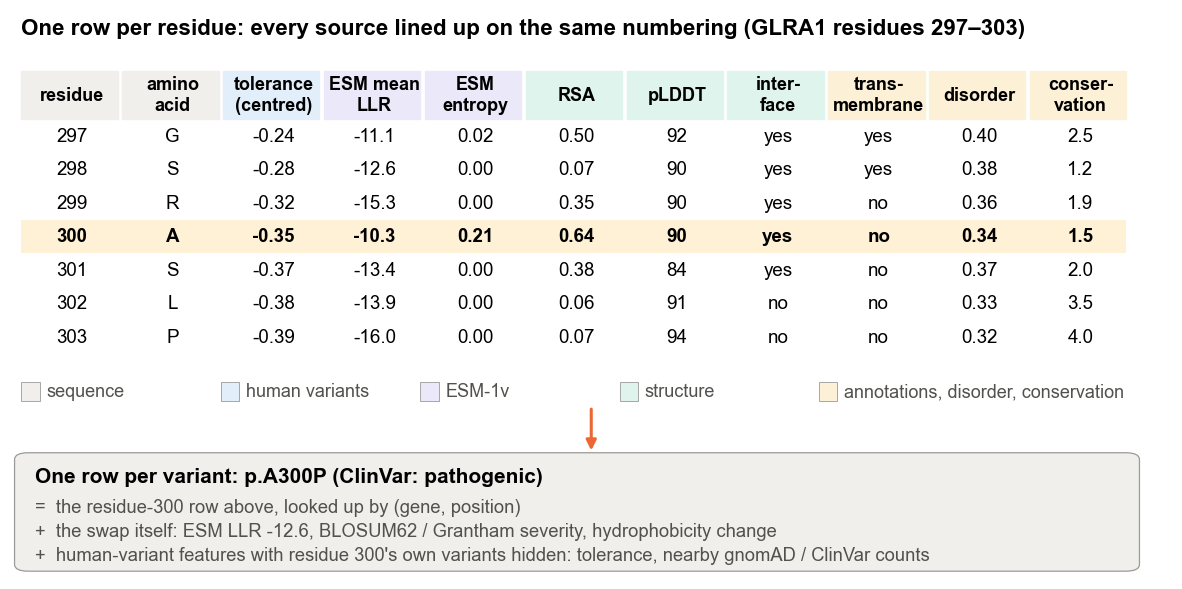

42 features per variant, in 7 groups: {'ESM scores': 4, 'human variants nearby': 7, 'gene-wide variant rates': 2, 'substitution type': 3, 'structure (§7)': 6, 'annotations (§8)': 16, 'disorder + conservation': 4}


In [15]:
rw = residue_df[(residue_df.gene == GENE) & residue_df.pos.between(VAR_POS - 3, VAR_POS + 3)].set_index("pos")
cols6 = [("tolerance_v4_centered", "tolerance\n(centred)", BLUE, "{:+.2f}"), ("esm_mean_llr", "ESM mean\nLLR", VIOLET, "{:.1f}"),
         ("esm_entropy", "ESM\nentropy", VIOLET, "{:.2f}"), ("rsa", "RSA", AQUA, "{:.2f}"), ("plddt", "pLDDT", AQUA, "{:.0f}"),
         ("iface_any", "inter-\nface", AQUA, "{}"), ("ann_transmembrane", "trans-\nmembrane", YELLOW, "{}"),
         ("disorder", "disorder", YELLOW, "{:.2f}"), ("msa_conservation", "conser-\nvation", YELLOW, "{:.1f}")]
fig, ax = plt.subplots(figsize=(15, 7.4)); ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.axis("off")
ax.text(0, 0.995, f"One row per residue: every source lined up on the same numbering ({GENE} residues {VAR_POS - 3}–{VAR_POS + 3})",
        fontsize=16, weight="bold", va="top")
heads = [("pos", "residue", "grey"), ("aa", "amino\nacid", "grey")] + [(c, h, colr) for c, h, colr, _ in cols6]
x0, cw, rh, top = 0.0, 0.0885, 0.06, 0.9
for j, (_, h, colr) in enumerate(heads):
    ax.add_patch(plt.Rectangle((x0 + j * cw, top - rh * 1.45), cw - 0.004, rh * 1.45, color=TINT.get(colr, TINT["grey"])))
    ax.text(x0 + j * cw + cw / 2, top - rh * 0.72, h, ha="center", va="center", fontsize=13, weight="bold")
for i, p in enumerate(rw.index):
    y = top - rh * 1.45 - (i + 1) * rh
    hl = p == VAR_POS
    if hl:
        ax.add_patch(plt.Rectangle((x0, y), cw * len(heads) - 0.004, rh, color="#fff1d6", lw=0))
    vals = [str(p), rw.loc[p, "aa"]] + [("–" if pd.isna(rw.loc[p, c]) else
                                       (("yes" if rw.loc[p, c] else "no") if fmt == "{}" else fmt.format(rw.loc[p, c])))
                                      for c, _, _, fmt in cols6]
    for j, val in enumerate(vals):
        ax.text(x0 + j * cw + cw / 2, y + rh / 2, val, ha="center", va="center", fontsize=13.5, weight="bold" if hl else "normal")
src_y = top - rh * 1.45 - 8.4 * rh
for k, (colr, labl) in enumerate([("grey", "sequence"), (BLUE, "human variants"), (VIOLET, "ESM-1v"), (AQUA, "structure"),
                                  (YELLOW, "annotations, disorder, conservation")]):
    ax.add_patch(plt.Rectangle((k * 0.175, src_y), 0.016, 0.034, color=TINT.get(colr, TINT["grey"]), ec="#9b9a96", lw=0.6))
    ax.text(k * 0.175 + 0.022, src_y + 0.017, labl, va="center", fontsize=13, color=INK2)
vrow = lab[(lab.gene == GENE) & (lab.protein_consequence == f"p.A{VAR_POS}P")].iloc[0]
ax.add_patch(FancyBboxPatch((0, 0.01), 0.975, 0.2, boxstyle="round,pad=0.006,rounding_size=0.012", fc=TINT["grey"], ec="#9b9a96", lw=0.9))
ax.text(0.012, 0.19, f"One row per variant: p.A{VAR_POS}P (ClinVar: {vrow.clinsig_group})", fontsize=15, weight="bold", va="top")
ax.text(0.012, 0.135, f"=  the residue-{VAR_POS} row above, looked up by (gene, position)\n"
        f"+  the swap itself: ESM LLR {vrow.esm_llr:.1f}, BLOSUM62 / Grantham severity, hydrophobicity change\n"
        f"+  human-variant features with residue {VAR_POS}'s own variants hidden: tolerance, nearby gnomAD / ClinVar counts",
        fontsize=13.2, va="top", color=INK2, linespacing=1.45)
ax.annotate("", (0.5, 0.215), (0.5, src_y - 0.01), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.2))
save(fig, "M4_residue_to_variant_row")
print(f"{len(ALL_VAR_FEATURES)} features per variant, in {len(VARIANT_GROUPS)} groups:",
      {g: len(c) for g, c in VARIANT_GROUPS.items()})

## 10. Results 1: every model and its AUROC
`R1_model_auroc_table.svg`

Every model's task is the same: separate ClinVar pathogenic / likely pathogenic from benign / likely benign variants (≥ 1 review star). The numbers are read from notebook 05's saved results, not typed in.
- **Cross-validation:** 15,339 variants in the training and validation genes (05 §14h). Five rounds, each holding out whole gene families, so every variant is scored by a model that never saw its gene or its relatives.
- **Untouched genes:** the final, one-time test on 1,357 variants in 85 genes never used for anything (05 §16). Only the models named in the test plan were run; the others are marked *not tested*.
- **"ESM unsure":** the 668 test variants that ESM-1v rates as mild (LLR above the median of benign training variants). This is where human data should matter most.

**What it shows.**
- **Model choice:** logistic regression on all 42 features was the best in cross-validation (0.961), matching gradient-boosted trees, an MLP, and CNN / BiLSTM networks that read the raw variant positions. As the simplest of the equally good models, it was chosen for the test.
- **Untouched genes:** it scored 0.890, against 0.620 for ESM-1v alone.

**Caption (copy-ready).** *Models compared by 5-fold cross-validation grouped by gene family (15,339 ClinVar variants, 716 genes). Logistic regression on 42 features matched more complex models and was pre-registered for a single test on 85 untouched genes. AUROC: 0.5 = chance, 1.0 = perfect.*

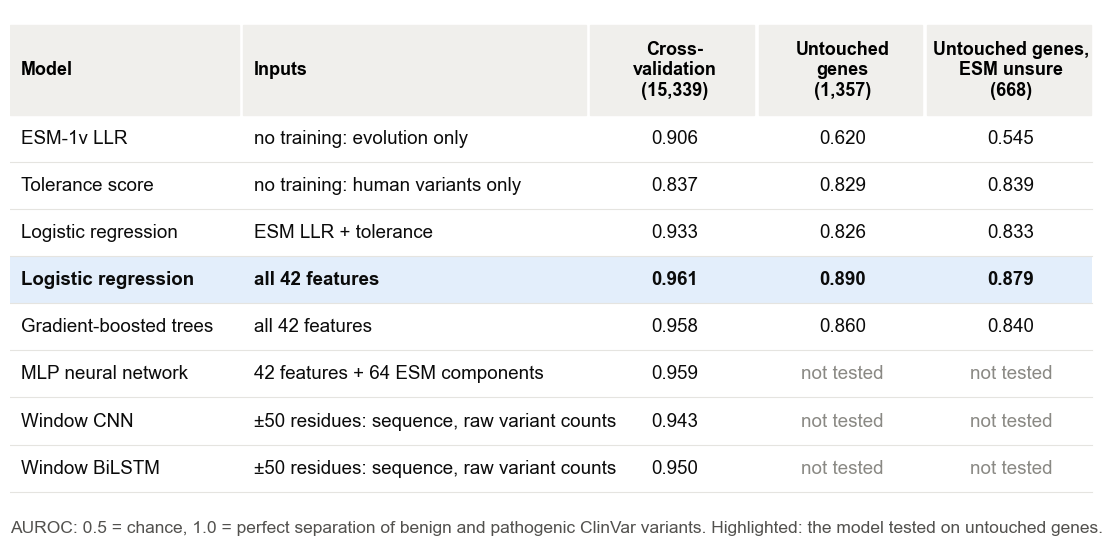

,model,inputs,cross-validation,untouched genes,"untouched, ESM unsure"
0,ESM-1v LLR,no training: evolution only,0.906,0.620,0.545
1,Tolerance score,no training: human variants only,0.837,0.829,0.839
2,Logistic regression,ESM LLR + tolerance,0.933,0.826,0.833
3,Logistic regression,all 42 features,0.961,0.890,0.879
4,Gradient-boosted trees,all 42 features,0.958,0.860,0.840
5,MLP neural network,42 features + 64 ESM components,0.959,not tested,not tested
6,Window CNN,"±50 residues: sequence, raw variant counts",0.943,not tested,not tested
7,Window BiLSTM,"±50 residues: sequence, raw variant counts",0.950,not tested,not tested


In [16]:
cv = pd.read_csv(os.path.join(OUT, "baselines", "variant_task_models.csv"), index_col=0)   # 05 §14h
test = pd.DataFrame(result["scores"]).T                                                      # 05 §16
MODELS_R1 = [  # name on the poster, its inputs, its name in the saved tables
    ("ESM-1v LLR", "no training: evolution only", "ESM-1v LLR"),
    ("Tolerance score", "no training: human variants only", "tolerance (own residue hidden)"),
    ("Logistic regression", "ESM LLR + tolerance", "logistic: ESM LLR + tolerance"),
    ("Logistic regression", "all 42 features", "logistic: all features"),
    ("Gradient-boosted trees", "all 42 features", "gradient-boosted trees: all features"),
    ("MLP neural network", "42 features + 64 ESM components", "MLP: all features + ESM representation"),
    ("Window CNN", "±50 residues: sequence, raw variant counts", "window CNN: raw variant tracks + sequence + LLR"),
    ("Window BiLSTM", "±50 residues: sequence, raw variant counts", "window BiLSTM: raw variant tracks + sequence + LLR"),
]
cell = lambda tab, key, col: f"{tab.loc[key, col]:.3f}" if key in tab.index else "not tested"
rows_t = [(m, inp, cell(cv, k, "AUROC"), cell(test, k, "AUROC"), cell(test, k, "AUROC where ESM is unsure")) for m, inp, k in MODELS_R1]
n_unsure = int((pred["ESM-1v LLR"] > lab.loc[lab.benign, "esm_llr"].median()).sum())

fig, ax = plt.subplots(figsize=(14, 6.8)); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
colx = [0.0, 0.215, 0.535, 0.69, 0.845]; widths = [0.215, 0.32, 0.155, 0.155, 0.155]
head1 = ["Model", "Inputs", f"Cross-\nvalidation\n({len(lab):,})", f"Untouched\ngenes\n({len(pred):,})",
         f"Untouched genes,\nESM unsure\n({n_unsure})"]
rh, ytop = 0.09, 0.97
for j, h in enumerate(head1):
    ax.add_patch(plt.Rectangle((colx[j], ytop - rh * 1.9), widths[j] - 0.004, rh * 1.9, color=TINT["grey"]))
    ax.text(colx[j] + (0.01 if j < 2 else widths[j] / 2), ytop - rh * 0.95, h, ha="left" if j < 2 else "center",
            va="center", fontsize=13, weight="bold", linespacing=1.15)
for i, r in enumerate(rows_t):
    y = ytop - rh * 1.9 - (i + 1) * rh
    best = r[1] == "all 42 features" and r[0].startswith("Logistic")
    if best:
        ax.add_patch(plt.Rectangle((0, y), 0.997, rh, color=TINT[BLUE], lw=0))
    for j, c_ in enumerate(r):
        ax.text(colx[j] + (0.01 if j < 2 else widths[j] / 2), y + rh / 2, c_, ha="left" if j < 2 else "center",
                va="center", fontsize=13.5, color=MUTED if c_ == "not tested" else INK, weight="bold" if best else "normal")
    ax.plot([0, 0.997], [y, y], color=GRID, lw=0.8)
ax.text(0, ytop - rh * 1.9 - 8.6 * rh, "AUROC: 0.5 = chance, 1.0 = perfect separation of benign and pathogenic ClinVar variants. "
        "Highlighted: the model tested on untouched genes.", fontsize=12.5, color=INK2, va="top")
save(fig, "R1_model_auroc_table")
pd.DataFrame(rows_t, columns=["model", "inputs", "cross-validation", "untouched genes", "untouched, ESM unsure"])

## 11. Results 2a: how the model scores a variant (Figure 21 of the guide)
`R2_logistic_regression_curve.svg`

**The model** is a logistic regression:
1. **Prepare.** Each of the 42 features is standardised (mean 0, spread 1). A missing value is filled with the median, plus a "was it missing?" flag.
2. **Weigh.** Each feature is multiplied by its learned weight, and the products are added into one number *z*.
3. **Squeeze.** The S-shaped logistic function turns *z* into a probability of being benign, between 0 and 1.

It was fitted once on all 15,339 training and validation variants, before the test genes were scored.

**Right panel.** The 1,357 test variants placed on that curve, coloured by their true ClinVar label (slightly jittered vertically). Pathogenic variants collect at low *z*, benign variants at high *z*.

**Note.** This figure shows *how* the model works and that test variants separate. It does not compare with ESM-1v; for that, put the next figure (ROC) or Results 3 beside it.

**Caption (copy-ready).** *The final model: a logistic regression combines 42 standardised features into one probability that a variant is benign. Right: the 1,357 ClinVar variants in 85 untouched genes along the fitted curve, coloured by their true classification.*

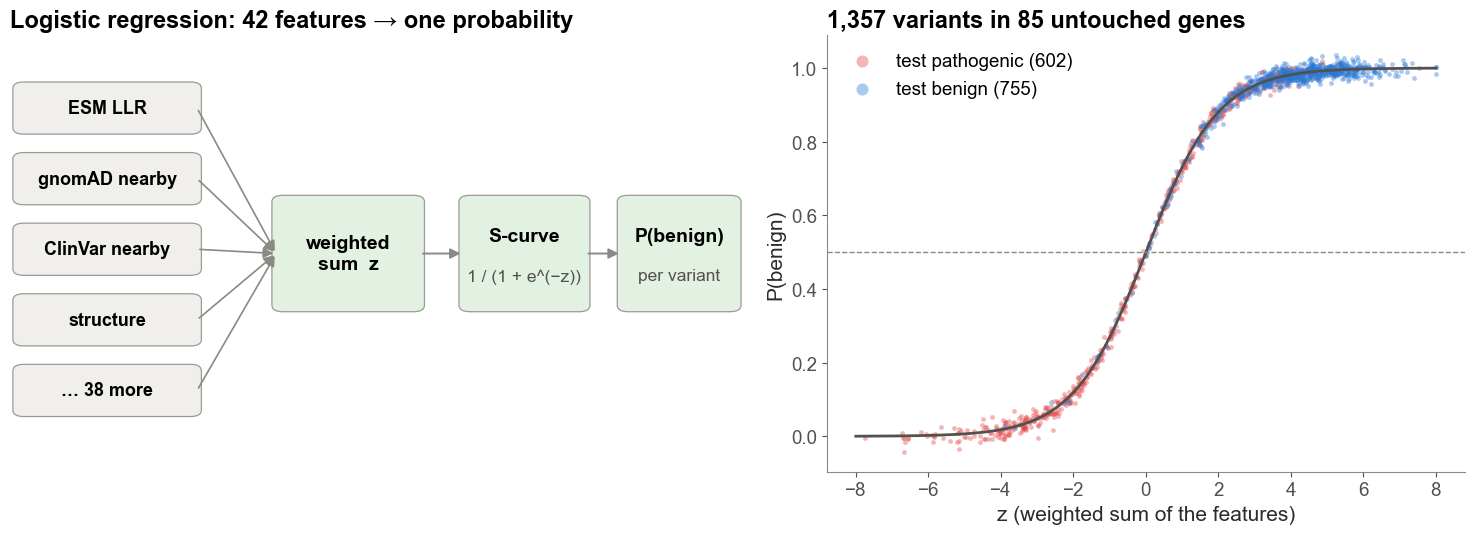

median P(benign): pathogenic 0.44, benign 0.99


In [17]:
p_t = pred[PRIMARY].clip(1e-6, 1 - 1e-6).to_numpy()
z = np.log(p_t / (1 - p_t))                                                  # back from probability to the weighted sum
y_t = pred.benign.to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]; ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.01); ax.axis("off")
for k, f in enumerate(["ESM LLR", "gnomAD nearby", "ClinVar nearby", "structure", f"… {len(ALL_VAR_FEATURES) - 4} more"]):
    yk = 0.84 - k * 0.165
    pbox(ax, 0.0, yk - 0.055, 0.25, 0.11, f, "", "grey", ts=13)
    ax.annotate("", (0.36, 0.5), (0.25, yk), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.2))
pbox(ax, 0.36, 0.37, 0.2, 0.26, "weighted\nsum  z", "", GREEN)
ax.annotate("", (0.62, 0.5), (0.56, 0.5), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.4))
pbox(ax, 0.62, 0.37, 0.17, 0.26, "S-curve", "1 / (1 + e^(−z))", GREEN)
ax.annotate("", (0.84, 0.5), (0.79, 0.5), arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=1.4))
pbox(ax, 0.84, 0.37, 0.16, 0.26, "P(benign)", "per variant", GREEN)
ax.set_title(f"Logistic regression: {len(ALL_VAR_FEATURES)} features → one probability")
ax = axes[1]
zz = np.linspace(-8, 8, 300)
ax.plot(zz, 1 / (1 + np.exp(-zz)), color=INK2, lw=2)
rng_j = np.random.default_rng(0)
for is_b, c, labl in [(False, RED, "pathogenic"), (True, BLUE, "benign")]:
    s_ = y_t == is_b; zc = np.clip(z[s_], -8, 8)
    ax.scatter(zc, 1 / (1 + np.exp(-zc)) + rng_j.normal(0, 0.014, s_.sum()), s=12, alpha=0.4, color=c, lw=0,
               label=f"test {labl} ({s_.sum()})")
ax.axhline(0.5, color=MUTED, ls="--", lw=1)
ax.set_xlabel("z (weighted sum of the features)"); ax.set_ylabel("P(benign)")
ax.set_title(f"{len(pred):,} variants in {pred.gene.nunique()} untouched genes")
ax.legend(frameon=False, markerscale=2.5, loc="upper left")
fig.tight_layout(); save(fig, "R2_logistic_regression_curve")
print(f"median P(benign): pathogenic {np.median(p_t[~y_t]):.2f}, benign {np.median(p_t[y_t]):.2f}")

## 12. Results 2b: better than ESM-1v on the untouched genes
`R2b_roc_untouched_genes.svg`

**An ROC curve** slides a cut-off from one end of the scores to the other. At every cut-off it plots the share of benign variants called benign (up) against the share of pathogenic variants wrongly called benign (right). A curve hugging the top-left corner is good; the diagonal is chance. The area under the curve is the AUROC.

- **Left:** all 1,357 test variants.
- **Right:** the 668 variants ESM-1v rates as mild. There, ESM-1v is at chance (0.54), while tolerance alone reaches 0.84 and the full model 0.88.

**Caption (copy-ready).** *ROC curves on 85 untouched genes. The model (AUROC 0.89) outperforms ESM-1v alone (0.62) and the tolerance score alone (0.83). Among variants ESM-1v rates as mild (right), ESM-1v is at chance (0.54) while the model reaches 0.88.*

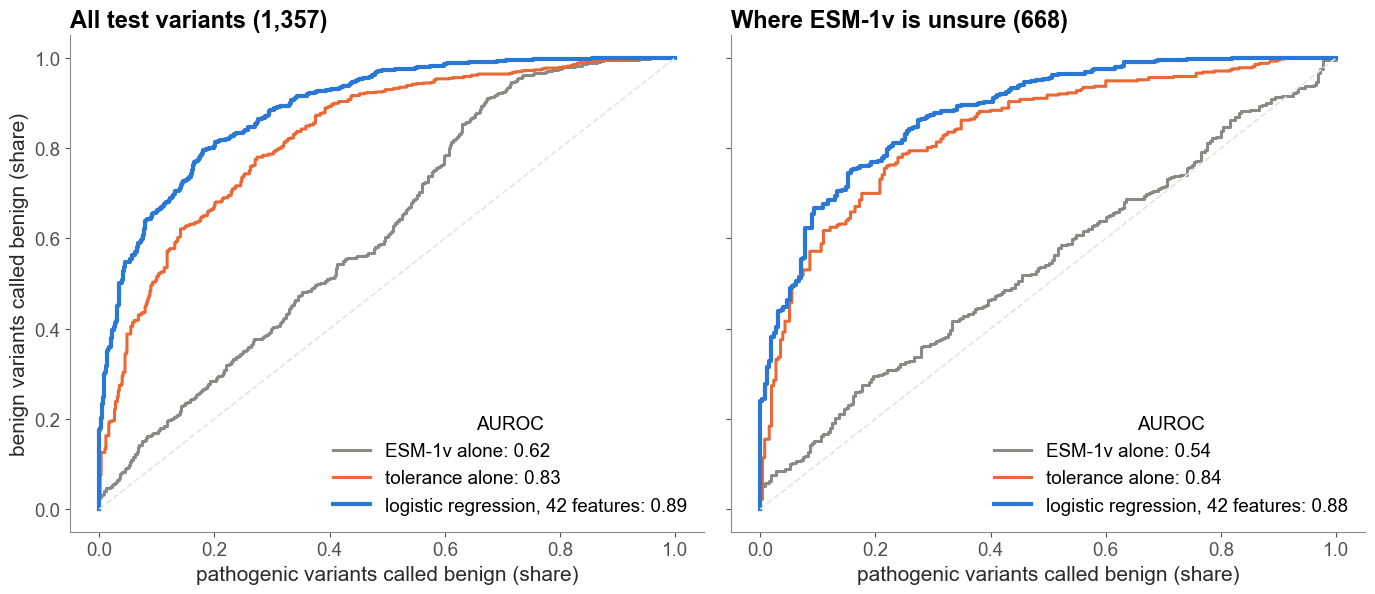

,ESM-1v alone,"logistic regression, 42 features",tolerance alone
All test variants,0.620,0.890,0.828
Where ESM-1v is unsure,0.545,0.879,0.839


In [18]:
UNSURE = lab.loc[lab.benign, "esm_llr"].median()               # threshold from TRAINING variants only (as in §16)
unsure_t = (pred["ESM-1v LLR"] > UNSURE).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
roc_table = {}
for ax, subset, title in [(axes[0], np.ones(len(pred), bool), f"All test variants ({len(pred):,})"),
                          (axes[1], unsure_t, f"Where ESM-1v is unsure ({unsure_t.sum()})")]:
    for name, c, lw, labl in [("ESM-1v LLR", MUTED, 2.2, "ESM-1v alone"), ("tolerance (own residue hidden)", ORANGE, 2.2, "tolerance alone"),
                              (PRIMARY, BLUE, 3.0, f"logistic regression, {len(ALL_VAR_FEATURES)} features")]:
        s_ = pred[name].to_numpy()[subset]
        fpr, tpr, _ = roc_curve(y_t[subset], s_)
        auc_ = roc_auc_score(y_t[subset], s_); roc_table[(title.split(" (")[0], labl)] = round(auc_, 3)
        ax.plot(fpr, tpr, color=c, lw=lw, label=f"{labl}: {auc_:.2f}")
    ax.plot([0, 1], [0, 1], color=GRID, ls="--", lw=1.2)
    ax.set_xlabel("pathogenic variants called benign (share)")
    ax.set_title(title); ax.legend(frameon=False, loc="lower right", title="AUROC", title_fontsize=13.5)
axes[0].set_ylabel("benign variants called benign (share)")
fig.tight_layout(); save(fig, "R2b_roc_untouched_genes")
pd.Series(roc_table).unstack()

## 13. Results 3: the pre-registered test on untouched genes
`R3_untouched_genes_vs_esm.svg`

**How the test was kept honest** (05 §16):
- **Separate genes:** the 85 test genes, in 55 gene families, were split off at the start and used for nothing else.
- **Plan first:** the model, the comparisons and the pass rule were saved, with a fingerprint, before any test variant was scored. The test ran once.
- **The pass rule:** each question compares two scores on the same variants. The 95% confidence interval (CI) of the difference comes from 1,000 resamples of whole test genes, and a difference counts as significant when the whole CI is above 0.

**What it shows.**
- **All variants and "ESM unsure":** the model beats ESM-1v significantly.
- **Within genes:** in each gene with ≥ 3 pathogenic and ≥ 3 benign variants, the direction is the same, but only 8 test genes qualify and the CI just touches 0.
- **A fourth pre-registered question,** whether ESM + tolerance beats ESM alone, also passed (Δ +0.21, 95% CI +0.02 to +0.30).

**Caveat for the small print.** Three genes (RYR1, ABL1, VHL) hold 52% of the test variants, and ESM-1v performs poorly in two of them. That inflates the all-variant gap. In the other 82 genes, the model and ESM-1v score 0.96 and 0.91.

**Caption (copy-ready).** *Pre-registered test on 85 untouched genes (1,357 ClinVar variants). The model outperformed ESM-1v on all variants (Δ AUROC +0.27, 95% CI +0.05 to +0.45) and where ESM-1v was uncertain (+0.34, +0.18 to +0.47). Within-gene comparisons (8 genes) did not reach significance.*

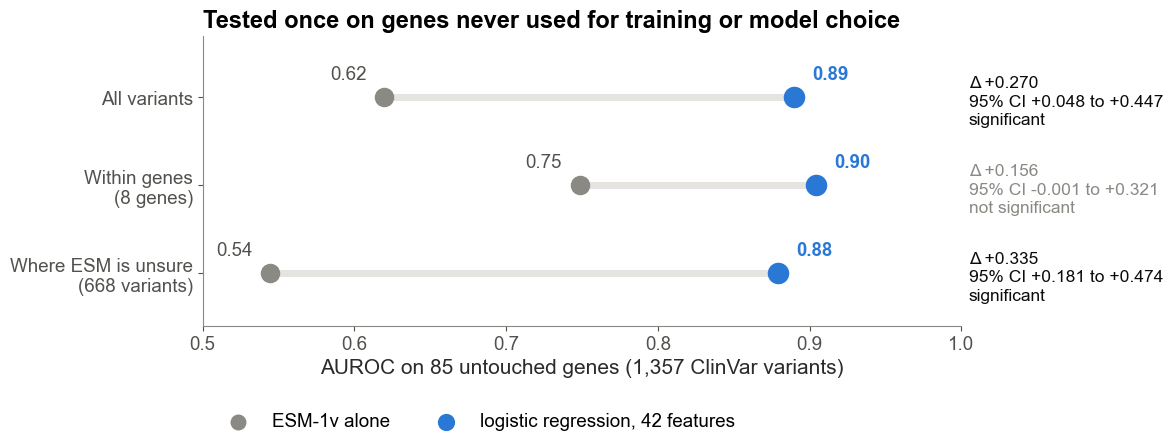

                                             difference      lo      hi passes
Q1: primary beats ESM-1v on all variants           0.27  0.0477  0.4472   True
Q2: primary beats ESM-1v within genes            0.1556 -0.0012  0.3207  False
Q3: primary beats ESM-1v where ESM is unsure     0.3345  0.1815   0.474   True
Q4: human variant data adds to ESM               0.2065  0.0209  0.2989   True

three genes hold 52% of test variants; in the other 82 genes: model 0.963 vs ESM-1v 0.911


In [19]:
sc, qs = result["scores"], result["questions"]
rowsR = [("All variants", "AUROC", "Q1: primary beats ESM-1v on all variants"),
         ("Within genes\n(8 genes)", "within-gene AUROC", "Q2: primary beats ESM-1v within genes"),
         (f"Where ESM is unsure\n({unsure_t.sum()} variants)", "AUROC where ESM is unsure", "Q3: primary beats ESM-1v where ESM is unsure")]
fig, ax = plt.subplots(figsize=(12, 5.2))
for k, (labl, key, q) in enumerate(rowsR):
    yk = len(rowsR) - 1 - k
    a, b = sc["ESM-1v LLR"][key], sc[PRIMARY][key]
    ax.plot([a, b], [yk, yk], color=GRID, lw=5, zorder=1, solid_capstyle="round")
    ax.scatter(a, yk, s=170, color=MUTED, zorder=3); ax.scatter(b, yk, s=210, color=BLUE, zorder=3)
    ax.text(a - 0.012, yk + 0.2, f"{a:.2f}", ha="right", fontsize=13.5, color=INK2)
    ax.text(b + 0.012, yk + 0.2, f"{b:.2f}", ha="left", fontsize=13.5, color=BLUE, weight="bold")
    qq = qs[q]
    ax.text(1.005, yk - 0.05, f"Δ {qq['difference']:+.3f}\n95% CI {qq['lo']:+.3f} to {qq['hi']:+.3f}\n"
            f"{'significant' if qq['passes'] else 'not significant'}",
            va="center", fontsize=12.5, color=INK if qq["passes"] else MUTED, linespacing=1.3)
ax.set_yticks(range(len(rowsR))[::-1], [r[0] for r in rowsR])
ax.set_xlim(0.5, 1.0); ax.set_ylim(-0.6, len(rowsR) - 0.3)
ax.set_xlabel(f"AUROC on {pred.gene.nunique()} untouched genes ({len(pred):,} ClinVar variants)")
ax.scatter([], [], s=110, color=MUTED, label="ESM-1v alone")
ax.scatter([], [], s=130, color=BLUE, label=f"logistic regression, {len(ALL_VAR_FEATURES)} features")
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, -0.42), ncol=2)
ax.set_title("Tested once on genes never used for training or model choice")
fig.tight_layout(); save(fig, "R3_untouched_genes_vs_esm")
big3 = ["RYR1", "ABL1", "VHL"]; rest = ~pred.gene.isin(big3)
print(pd.DataFrame(qs).T[["difference", "lo", "hi", "passes"]].to_string())
print(f"\nthree genes hold {pred.gene.isin(big3).mean():.0%} of test variants; in the other {pred[rest].gene.nunique()} genes: "
      f"model {roc_auc_score(y_t[rest], pred.loc[rest, PRIMARY]):.3f} vs ESM-1v {roc_auc_score(y_t[rest], pred.loc[rest, 'ESM-1v LLR']):.3f}")

## 14. Results 4a: what each data type adds (Figure 23 of the guide)
`R4_feature_groups.svg`

**Data.** These are the 05 §14h ablation runs: the gradient-boosted tree model refitted with different groups of features, each cross-validated on the 15,339 training and validation variants (whole gene families held out per round). The cached predictions are re-scored here.

**Panel A, each group on its own.** How much each data type knows by itself (dark: all variants; light: within genes).
- **Strong groups:** ESM (0.90), human variants nearby (0.89), disorder + conservation (0.89) and structure (0.88) are each strong alone.
- **Gene-wide rates** drop to chance within genes (0.51), because they are the same for every variant of a gene.

**Panel B, each group added to the ESM scores.** The direct test of the hypothesis: does a data type improve on evolution alone? Bars are the AUROC gained; error bars are 95% CIs from 500 paired resamples of whole genes.
- **Significant gains:** human variants nearby +0.029 (+0.018 to +0.040), structure +0.036 (+0.014 to +0.066), disorder + conservation +0.040 (+0.015 to +0.076).
- **Gene-wide rates:** their CI crosses 0.
- **Within genes:** the gains are smaller (+0.009 to +0.017).

**Takeaway.** Human population data add real information beyond evolution. Structure and disorder add a similar amount, and the three overlap because all of them mark constrained regions. Together, all features reach 0.958, against 0.904 for the ESM scores alone.

**Caption (copy-ready).** *Contribution of each feature group (gradient-boosted trees, cross-validated). (A) AUROC of each group alone. (B) AUROC gained when each group is added to the ESM scores; error bars, 95% CI from gene-level resampling. Human-variant density adds significantly to ESM (+0.029), comparable to structure (+0.036) and disorder + conservation (+0.040).*

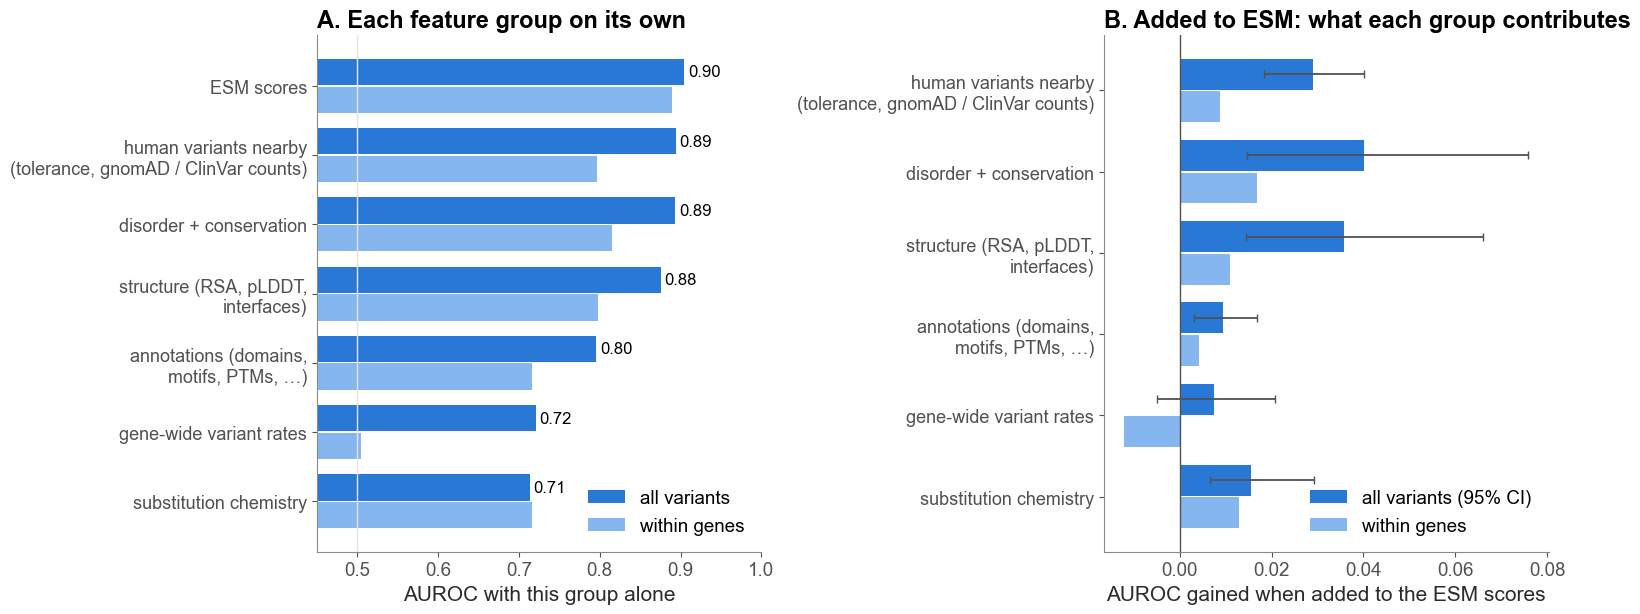

ESM scores alone 0.904 | all features 0.958


,alone,alone_within,gain,gain_lo,gain_hi,gain_within
group,,,,,,
ESM scores,0.904,0.889,NaN,NaN,NaN,NaN
human variants nearby,0.894,0.797,0.029,0.018,0.040,0.009
gene-wide variant rates,0.721,0.505,0.007,-0.005,0.021,-0.012
substitution type,0.713,0.716,0.015,0.007,0.029,0.013
structure (§7),0.875,0.798,0.036,0.014,0.066,0.011
annotations (§8),0.795,0.716,0.009,0.003,0.017,0.004
disorder + conservation,0.893,0.816,0.040,0.015,0.076,0.017


In [20]:
group_pred = pd.read_parquet(os.path.join(OUT, "baselines", "ablation_variant_features.parquet"))   # 05 §14h, cached
y_lab_, genes_lab = lab.benign.to_numpy(), lab.gene.to_numpy()
esm_only = group_pred["only ESM scores"].to_numpy()


def within_auc(s):
    # mean AUROC inside genes with >= 3 pathogenic and >= 3 benign variants
    rows_of = pd.Series(np.arange(len(s))).groupby(genes_lab).indices
    return float(np.mean([roc_auc_score(y_lab_[i], s[i]) for i in rows_of.values() if 3 <= y_lab_[i].sum() <= len(i) - 3]))


NICE = {"ESM scores": "ESM scores", "human variants nearby": "human variants nearby\n(tolerance, gnomAD / ClinVar counts)",
        "gene-wide variant rates": "gene-wide variant rates", "substitution type": "substitution chemistry",
        "structure (§7)": "structure (RSA, pLDDT,\ninterfaces)", "annotations (§8)": "annotations (domains,\nmotifs, PTMs, …)",
        "disorder + conservation": "disorder + conservation"}
rows4 = []
for g in VARIANT_GROUPS:
    alone = group_pred[f"only {g}"].to_numpy()
    r = {"group": g, "alone": roc_auc_score(y_lab_, alone), "alone_within": within_auc(alone)}
    if g != "ESM scores":
        plus = group_pred[f"ESM + {g}"].to_numpy()
        r["gain"] = roc_auc_score(y_lab_, plus) - roc_auc_score(y_lab_, esm_only)
        stat = lambda rows, a=plus: roc_auc_score(y_lab_[rows], a[rows]) - roc_auc_score(y_lab_[rows], esm_only[rows])
        r["gain_lo"], r["gain_hi"] = gene_bootstrap(stat, genes_lab, n=500)     # paired: same genes for both models
        r["gain_within"] = within_auc(plus) - within_auc(esm_only)
    rows4.append(r)
abl = pd.DataFrame(rows4).set_index("group")
order = abl.sort_values("alone").index

fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
yy = np.arange(len(order))
ax = axes[0]
ax.barh(yy + 0.2, abl.loc[order, "alone"], height=0.38, color=BLUE, label="all variants")
ax.barh(yy - 0.2, abl.loc[order, "alone_within"], height=0.38, color="#86b6ef", label="within genes")
for k, g in enumerate(order):
    ax.text(abl.loc[g, "alone"] + 0.005, k + 0.2, f"{abl.loc[g, 'alone']:.2f}", va="center", fontsize=12)
ax.set_xlim(0.45, 1.0); ax.axvline(0.5, color=GRID, lw=1)
ax.set_yticks(yy, [NICE[g] for g in order], fontsize=13)
ax.set_xlabel("AUROC with this group alone"); ax.legend(frameon=False, loc="lower right")
ax.set_title("A. Each feature group on its own")
ax = axes[1]
order2 = [g for g in order if g != "ESM scores"]; yy2 = np.arange(len(order2))
gain = abl.loc[order2, "gain"].to_numpy(float)
ax.barh(yy2 + 0.2, gain, height=0.38, color=BLUE, label="all variants (95% CI)",
        xerr=[gain - abl.loc[order2, "gain_lo"].to_numpy(float), abl.loc[order2, "gain_hi"].to_numpy(float) - gain],
        error_kw=dict(ecolor=INK2, lw=1.3, capsize=3))
ax.barh(yy2 - 0.2, abl.loc[order2, "gain_within"].to_numpy(float), height=0.38, color="#86b6ef", label="within genes")
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(yy2, [NICE[g] for g in order2], fontsize=13)
ax.set_xlabel("AUROC gained when added to the ESM scores"); ax.legend(frameon=False, loc="lower right")
ax.set_title("B. Added to ESM: what each group contributes")
fig.tight_layout(); save(fig, "R4_feature_groups")
print(f"ESM scores alone {roc_auc_score(y_lab_, esm_only):.3f} | all features "
      f"{roc_auc_score(y_lab_, pd.read_parquet(os.path.join(OUT, 'baselines', 'variant_predictions.parquet'))['gradient-boosted trees: all features']):.3f}")
abl.round(3)

## 15. Results 4b: what the final model relies on (Figure 26 of the guide)
`R5_model_weights.svg`

**Data.** The final logistic regression is refitted here exactly as in 05 §16c (same 15,339 variants, same settings). The fit is deterministic, so these are the same weights as in the official run.

**How to read a bar.** It shows how much the model's log-odds of "benign" change when that feature rises by one standard deviation, with all other features held fixed. Blue pushes towards benign, red towards pathogenic.

**What it shows.**
- **The ESM-1v LLR dominates** (+1.53): a less surprising substitution looks benign.
- **Local human variation comes next:**
  - more gnomAD variants within ±15 residues → benign (+1.07);
  - more ClinVar variants within ±15 → pathogenic (−0.99).
- **Then conservation, structure and the swap itself:**
  - conservation (more conserved → pathogenic, −0.90);
  - interfaces (→ pathogenic, −0.49);
  - solvent exposure (exposed → benign, +0.44);
  - substitution severity (drastic → pathogenic, −0.40).
- **One counter-intuitive pair:** the whole-gene ClinVar rate is *positive* (+0.85) beside the negative local count. Together they mean the model compares local ClinVar density with the gene's average: an *excess* near the variant signals pathogenicity. gnomAD works the same way (local +1.07, gene-wide −0.26).
- **The tolerance score itself gets a modest weight (+0.29)** because the raw counts carry the same information and the credit is split. Correlated features share weight, so no single bar is an independent effect.

**Caption (copy-ready).** *Largest weights of the final model (per standard deviation; blue → benign, red → pathogenic). The ESM-1v LLR dominates, followed by local human variation: gnomAD variants nearby (benign) and ClinVar variants nearby (pathogenic), then conservation, interfaces, solvent exposure and substitution severity.*

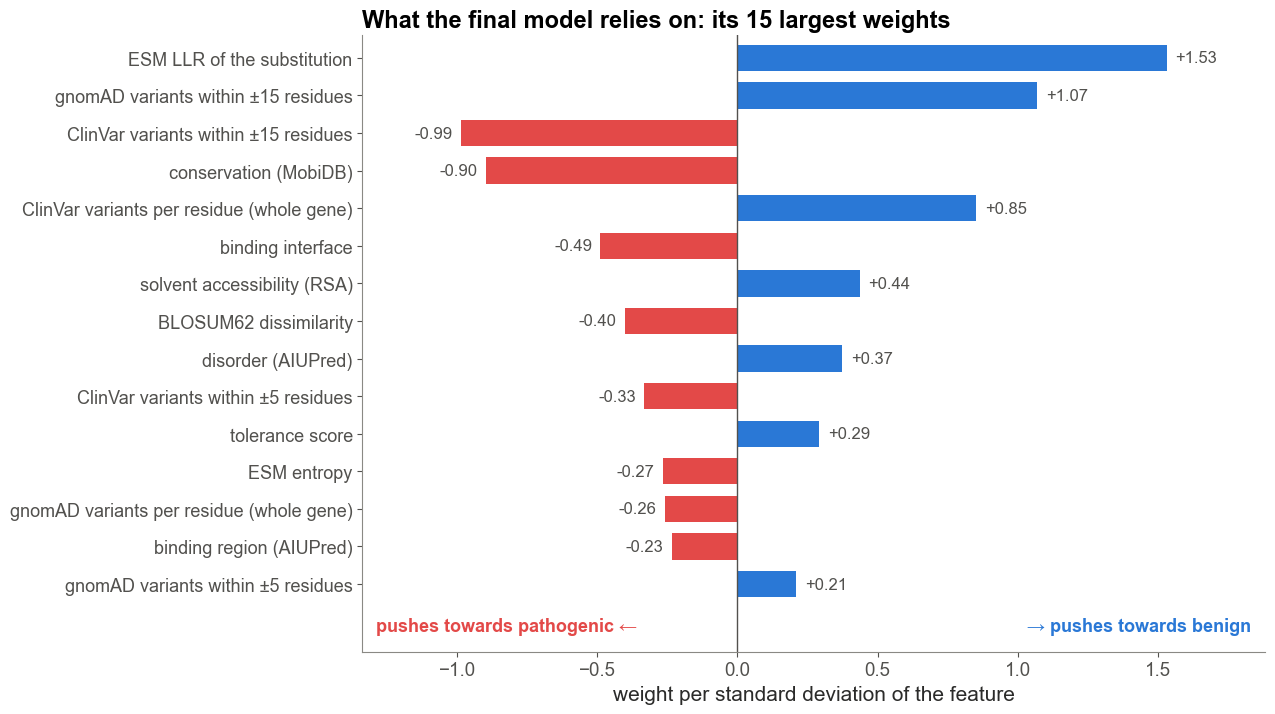

,weight
esm_llr,1.53
gnomad_within_15,1.07
clinvar_within_15,-0.99
msa_conservation,-0.90
clinvar_per_residue,0.85
iface_any,-0.49
rsa,0.44
blosum62,-0.40
disorder,0.37
clinvar_within_5,-0.33


In [21]:
final = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), LogisticRegression(max_iter=5000))
final.fit(lab[ALL_VAR_FEATURES].to_numpy(), lab.benign.to_numpy())            # = 05 §16c (deterministic)
names = final[:-1].get_feature_names_out()                                    # 'x12' = feature 12; 'missingindicator_x12' = its flag
coef = pd.Series(final[-1].coef_[0], index=names)
weights = pd.Series({ALL_VAR_FEATURES[int(n[1:])]: w for n, w in coef.items() if n.startswith("x")})
PLAIN = {"esm_llr": "ESM LLR of the substitution", "gnomad_within_15": "gnomAD variants within ±15 residues",
         "clinvar_within_15": "ClinVar variants within ±15 residues", "msa_conservation": "conservation (MobiDB)",
         "clinvar_per_residue": "ClinVar variants per residue (whole gene)", "iface_any": "binding interface",
         "rsa": "solvent accessibility (RSA)", "blosum62": "BLOSUM62 dissimilarity", "disorder": "disorder (AIUPred)",
         "clinvar_within_5": "ClinVar variants within ±5 residues", "tolerance": "tolerance score",
         "esm_entropy": "ESM entropy", "gnomad_per_residue": "gnomAD variants per residue (whole gene)",
         "binding": "binding region (AIUPred)", "gnomad_within_5": "gnomAD variants within ±5 residues",
         "esm_mean_llr": "ESM mean LLR", "esm_wt_lp": "ESM wild-type log-prob", "grantham": "Grantham distance",
         "hydrophobicity_change": "hydrophobicity change", "plddt": "AlphaFold pLDDT", "gnomad_density": "gnomAD density",
         "clinvar_density": "ClinVar density"}
top = weights.reindex(weights.abs().sort_values(ascending=False).index[:15])
fig, ax = plt.subplots(figsize=(13, 7.4))
yy = np.arange(len(top))[::-1]
ax.barh(yy, top, color=[BLUE if w > 0 else RED for w in top], height=0.7)
for y_i, (f, w) in zip(yy, top.items()):
    ax.text(w + (0.03 if w > 0 else -0.03), y_i, f"{w:+.2f}", va="center", ha="left" if w > 0 else "right", fontsize=12, color=INK2)
ax.set_yticks(yy, [PLAIN.get(f, f) for f in top.index], fontsize=13)
ax.axvline(0, color=INK2, lw=1)
ax.set_xlim(top.min() - 0.35, top.max() + 0.35)
ax.set_xlabel("weight per standard deviation of the feature")
ax.text(top.max() + 0.3, -1.25, "→ pushes towards benign", ha="right", color=BLUE, fontsize=13, weight="bold")
ax.text(top.min() - 0.3, -1.25, "pushes towards pathogenic ←", ha="left", color=RED, fontsize=13, weight="bold")
ax.set_ylim(-1.8, len(top) - 0.4)
ax.set_title("What the final model relies on: its 15 largest weights")
fig.tight_layout(); save(fig, "R5_model_weights")
top.round(2).to_frame("weight")

## 16. Take-home message and limits

**Take-home (copy-ready).** *Human population variation adds information that evolution alone (ESM-1v) misses. A simple model combining gnomAD / ClinVar variant density with ESM-1v, structure and annotations classified ClinVar variants in untouched genes with AUROC 0.89, against 0.62 for ESM-1v. The gain was largest where ESM-1v was uncertain (0.88 vs 0.54).*

**Limits worth stating on the poster.**
- **Three genes dominate the test set.** RYR1, ABL1 and VHL hold 52% of the test variants, which inflates the all-variant gap; in the other 82 genes the model scores 0.96 and ESM-1v 0.91.
- **The probabilities are not yet calibrated.** At P(benign) ≥ 0.5, 97% of benign but only 52% of pathogenic test variants were classified correctly. Use the output as a ranking.
- **Performance on VUS is not yet measured.** The test used confidently classified variants; VUS are harder. A time-split test with older ClinVar releases would measure it directly.
- **Tolerance counts every ClinVar submission.** Its ClinVar side includes VUS, so VUS clusters partly reflect submission patterns.

The last cell saves every number quoted above to `poster/poster_numbers.json`.

In [22]:
numbers = {"held_out_groups": group_stats, "roc_untouched": {f"{a} | {b}": v for (a, b), v in roc_table.items()},
           "test_questions": result["questions"], "test_scores": result["scores"],
           "feature_groups": abl.round(4).to_dict(orient="index"), "weights_top15": top.round(3).to_dict(),
           "esm_unsure_threshold": float(UNSURE), "plan_id": result["plan_id"], "test_run": result["run"]}
json.dump(numbers, open(os.path.join(POSTER, "poster_numbers.json"), "w"), indent=1, default=float)
print("saved", os.path.join(POSTER, "poster_numbers.json"))
print("SVG files:", sorted(f for f in os.listdir(SVG) if f.endswith(".svg")))

saved /Users/awlehr/LehrPDI/figures/results/tolerance_model/poster/poster_numbers.json
SVG files: ['I0_conservation_phylogeny.svg', 'I1_esm_by_variant_group.svg', 'M0_tolerance_diagram.svg', 'M1_tolerance_score_build.svg', 'M2_tolerance_by_variant_group.svg', 'M3_structural_feature_tracks.svg', 'M3a_glra1_structure_overview.svg', 'M3b_core_vs_surface.svg', 'M3c_interfaces.svg', 'M3d_annotation_sources.svg', 'M4_residue_to_variant_row.svg', 'R1_model_auroc_table.svg', 'R2_logistic_regression_curve.svg', 'R2b_roc_untouched_genes.svg', 'R3_untouched_genes_vs_esm.svg', 'R4_feature_groups.svg', 'R5_model_weights.svg']
